# RL + SCED Results â€” IEEE 9-Bus

Visualizes how RL agents learn strategic bidding in the Egret SCED market.
RL agents are auto-discovered from `bid_history.csv` â€” add more RL generators in
`learning_runner.py` and the notebook adapts automatically.

**Data sources:**
- `testbed_results/rl_episodes/bid_history.csv` â€” raw bid prices from RL strategies per episode
- `testbed_results/rl_final/` â€” final evaluation CSVs (market_orders, market_meta, market_dispatch, etc.)

**Sections:**
1. Run training (configurable via `scenarios.yaml`)
2. Bid evolution across training episodes
3. Bid price distributions per episode
4. Hourly bid profiles (early vs late episodes)
5. Strategic markup summary
6. Final evaluation: dispatch, LMPs, nodal view, generator economics

Training is configured in `scenarios.yaml` under each scenario's `training:` section.
Run the cell below to train, or skip if results already exist.

In [18]:
# ============================================================
# CONFIG â€” Change SCENARIO here, then run cells in order
# ============================================================
SCENARIO =  'base_profit_sac'  # 'base_profit_sac', 'base', 'congested'

# --- Run RL Training ---
# Uses the scenario's training settings from scenarios.yaml,
# including the algorithm (matd3, sac, or ppo).
# Skip this cell (run from the next cell) if results already exist.

import subprocess, sys, yaml

# Read algorithm from scenarios.yaml
with open('scenarios.yaml') as f:
    _all_scenarios = yaml.safe_load(f)
_training_cfg = _all_scenarios[SCENARIO].get('training', {})
ALGORITHM = _training_cfg.get('algorithm', 'matd3')

result = subprocess.run(
    [sys.executable, '-m', 'testbed.learning_runner',
     '--scenario', SCENARIO, '--algorithm', ALGORITHM],
    capture_output=True, text=True, cwd='..',
)
print(f'Scenario: {SCENARIO}, Algorithm: {ALGORITHM}')
print(result.stdout[-2000:] if len(result.stdout) > 2000 else result.stdout)
if result.returncode != 0:
    print('STDERR:', result.stderr[-1000:] if len(result.stderr) > 1000 else result.stderr)

Scenario: base_profit_sac, Algorithm: sac
68.229', '277.079', '259.700', '258.270', '281.054', '277.204', '255.465', '259.429', '277.469', '263.063', '257.922', '255.738', '255.201', '257.262', '264.160', '260.924', '256.359', '254.807', '264.451', '265.088', '258.259', '261.373', '260.410', '255.647', '252.268', '256.175', '254.398', '252.868', '260.161', '259.648', '251.479', '256.639', '266.724', '256.866', '258.775', '257.548', '261.089', '256.707', '254.205', '255.097', '259.544', '253.739', '257.623', '262.955', '257.639', '267.241', '261.105', '256.759', '257.910', '254.868', '255.809', '255.090', '259.879', '260.185', '263.019', '256.749', '259.934', '256.854', '253.721', '255.522', '257.360', '255.442', '253.876', '251.847', '261.994', '264.973', '267.747', '263.793', '258.598', '252.211', '255.947', '259.661', '253.610', '256.791', '255.945', '257.198', '251.957', '253.201', '255.573', '255.774', '258.614', '259.808', '255.765', '262.496', '258.777', '267.546', '262.408', '25

In [1]:
import sys, os, importlib
from datetime import timedelta

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# Ensure testbed modules are importable
testbed_dir = os.path.abspath('.')
repo_root = os.path.abspath('..')
for p in [testbed_dir, repo_root]:
    if p not in sys.path:
        sys.path.insert(0, p)

from ieee9_network import build_ieee9_network
from clearing.sced_clearing import clear_sced

import nodal_plot
importlib.reload(nodal_plot)
from nodal_plot import (
    plot_nodal_circlize, plot_network_topology,
    assign_bus_colors, compute_ptdf_flows,
    BUS_PALETTE, TRANSIT_COLOR, _darken,
)

# ============================================================
# CONFIG — Set SCENARIO here (same as cell 1, whichever runs first wins)
# ============================================================
SCENARIO = 'base_profit_matd3'  # 'base', 'congested', 'base_profit_dsac', etc.
FINAL_DIR = '../testbed_results/rl_final/ieee9_rl_egret_sced'
PLOT_HOUR = 12  # hour for nodal detail views
FOCUS_AGENT = None  # RL agent for best-episode selection (None = first RL agent)
# ============================================================

# Load scenario config (for line overrides, load profile, algorithm, etc.)
with open('scenarios.yaml') as f:
    all_scenarios = yaml.safe_load(f)
assert SCENARIO in all_scenarios, f"Unknown scenario '{SCENARIO}'. Available: {list(all_scenarios.keys())}"
scenario_cfg = all_scenarios[SCENARIO]
scenario_name = scenario_cfg['name']
line_overrides = scenario_cfg.get('line_overrides', {})

# Algorithm and results directory from scenario config
ALGORITHM = scenario_cfg.get('training', {}).get('algorithm', 'matd3')
RESULTS_DIR = '../' + scenario_cfg.get('training', {}).get('results_dir', f'testbed_results/rl_{ALGORITHM}')

print(f'Scenario: {scenario_name}')
print(f'Algorithm: {ALGORITHM}')
print(f'Results dir: {RESULTS_DIR}')
if line_overrides:
    print(f'Line overrides: {line_overrides}')
else:
    print('Line overrides: none (default capacities)')

# Load bid history (recorded during training — only contains RL agents)
bids_df = pd.read_csv(f'{RESULTS_DIR}/bid_history.csv', parse_dates=['timestamp'])
bids_df['hour'] = bids_df['timestamp'].dt.hour

# Auto-discover RL agents from bid history
RL_AGENTS = sorted(bids_df['unit_id'].unique())

# Resolve FOCUS_AGENT
if FOCUS_AGENT is None:
    FOCUS_AGENT = RL_AGENTS[0]
assert FOCUS_AGENT in RL_AGENTS, f"FOCUS_AGENT '{FOCUS_AGENT}' not in RL agents: {RL_AGENTS}"

# Build network to get generator metadata (MC, bus, capacity) for all generators
_network = build_ieee9_network(periods=1)
_gen_df = _network.generators

# Build MC, bus, and nameplate capacity lookup for ALL generators
gen_mc = {name: float(row['marginal_cost']) for name, row in _gen_df.iterrows()}
gen_bus = {name: str(row['bus']) for name, row in _gen_df.iterrows()}
gen_capacity = {name: float(row['p_nom']) for name, row in _gen_df.iterrows()}
RL_GENERATORS = set(RL_AGENTS)

# MC subset for RL agents only (used in evolution plots)
MC = {u: gen_mc[u] for u in RL_AGENTS}

# Assign colors: RL agents get palette colors based on their bus index
UNIT_COLORS = {}
for i, unit in enumerate(RL_AGENTS):
    bus = gen_bus[unit]
    bus_idx = sorted(_gen_df['bus'].unique()).index(bus)
    UNIT_COLORS[unit] = BUS_PALETTE[bus_idx % len(BUS_PALETTE)]

# --- Bid type handling ---
# bid_type comes from the training recorder:
#   "single" = WithholdingStrategy (1 bid: price + volume control)
#   "pmin"/"flex" = EnergyLearningStrategy (2-part: Pmin block + flexible remainder)
# For backwards compat with old CSVs that only have "pmin" from single-bid strategies,
# detect and reclassify: if ALL bids are "pmin" and no "flex" exists, treat as "single".
raw_types = set(bids_df['bid_type'].unique())
if raw_types == {'pmin'}:
    print('NOTE: All bids labeled "pmin" (old format) — reclassifying as "single"')
    bids_df['bid_type'] = 'single'
    raw_types = {'single'}

# "primary_bids" = the main price signal for evolution plots
# For 2-part strategies: flex bids carry the strategic price signal
# For single-bid strategies: the single bid IS the price signal
SINGLE_BID_MODE = 'single' in raw_types and 'flex' not in raw_types
if SINGLE_BID_MODE:
    primary_bids = bids_df.copy()  # all bids are primary
    BID_LABEL = 'Bid'  # label for plots (not "Flex")
else:
    primary_bids = bids_df[bids_df['bid_type'] == 'flex'].copy()
    BID_LABEL = 'Flex Bid'

print(f'Loaded {len(bids_df)} bid records across {bids_df["episode"].nunique()} episodes')
print(f'RL agents: {RL_AGENTS}')
print(f'Focus agent: {FOCUS_AGENT} (used for best-episode selection)')
print(f'Bid mode: {"single (price+volume)" if SINGLE_BID_MODE else "2-part (pmin+flex)"}')
for u in RL_AGENTS:
    print(f'  {u}: bus {gen_bus[u]}, MC=${gen_mc[u]:.0f}, capacity={gen_capacity[u]:.0f} MW')
print(f'Bid types: {bids_df["bid_type"].value_counts().to_dict()}')

Scenario: Base Case — Pure Profit Reward
Algorithm: matd3
Results dir: ../testbed_results/rl_matd3
Line overrides: none (default capacities)
Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
Loaded 22000 bid records across 1000 episodes
RL agents: ['gen_0']
Focus agent: gen_0 (used for best-episode selection)
Bid mode: single (price+volume)
  gen_0: bus 2, MC=$35, capacity=300 MW
Bid types: {'single': 22000}


## 1. Bid Price Evolution Across Episodes

Average bid price per episode for each RL agent.
Dashed lines show marginal costs. Bids above MC = strategic markup.
In single-bid mode (withholding), volume evolution is shown on the secondary axis.

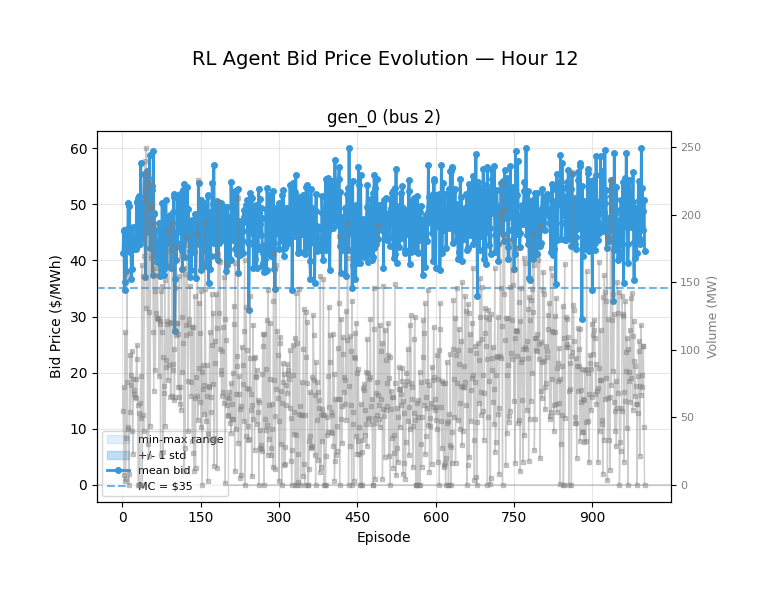

In [2]:
# Bid evolution — bid price per episode for PLOT_HOUR only (RL agents only)
# Uses primary_bids (flex for 2-part, all bids for single-bid mode)
n_agents = len(RL_AGENTS)
fig, axes = plt.subplots(1, n_agents, figsize=(7 * n_agents, 5), sharey=True, squeeze=False)
axes = axes.flatten()

for ax, unit in zip(axes, RL_AGENTS):
    unit_bids = primary_bids[(primary_bids['unit_id'] == unit) & (primary_bids['hour'] == PLOT_HOUR)]
    ep_stats = unit_bids.groupby('episode').agg(
        price_mean=('bid_price', 'mean'),
        price_min=('bid_price', 'min'),
        price_max=('bid_price', 'max'),
        price_std=('bid_price', 'std'),
        vol_mean=('bid_volume', 'mean'),
    )

    color = UNIT_COLORS[unit]
    ax.fill_between(ep_stats.index, ep_stats['price_min'], ep_stats['price_max'],
                     alpha=0.15, color=color, label='min-max range')
    ax.fill_between(ep_stats.index,
                     ep_stats['price_mean'] - ep_stats['price_std'].fillna(0),
                     ep_stats['price_mean'] + ep_stats['price_std'].fillna(0),
                     alpha=0.3, color=color, label='+/- 1 std')
    ax.plot(ep_stats.index, ep_stats['price_mean'], '-o', color=color,
            linewidth=2, markersize=4, label=f'mean {BID_LABEL.lower()}')
    ax.axhline(MC[unit], color=color, linestyle='--', alpha=0.7,
               label=f'MC = ${MC[unit]:.0f}')
    ax.axhline(0, color='gray', linestyle='-', alpha=0.3)

    # In single-bid mode, show volume evolution on secondary axis
    if SINGLE_BID_MODE:
        ax2 = ax.twinx()
        ax2.plot(ep_stats.index, ep_stats['vol_mean'], '-s', color='gray',
                 alpha=0.4, linewidth=1, markersize=3, label='avg volume')
        ax2.set_ylabel('Volume (MW)', color='gray', fontsize=9)
        ax2.tick_params(axis='y', labelcolor='gray', labelsize=8)

    ax.set_xlabel('Episode')
    ax.set_ylabel(f'{BID_LABEL} Price ($/MWh)')
    ax.set_title(f'{unit} (bus {gen_bus[unit]})')
    ax.legend(loc='best', fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

fig.suptitle(f'RL Agent {BID_LABEL} Price Evolution — Hour {PLOT_HOUR}', fontsize=14, y=1.02)
plt.tight_layout()

## 2. Bid Price Distributions per Episode

Box plots showing how bid price variance changes as agents learn.
Early episodes have high variance (exploration noise); later episodes converge.

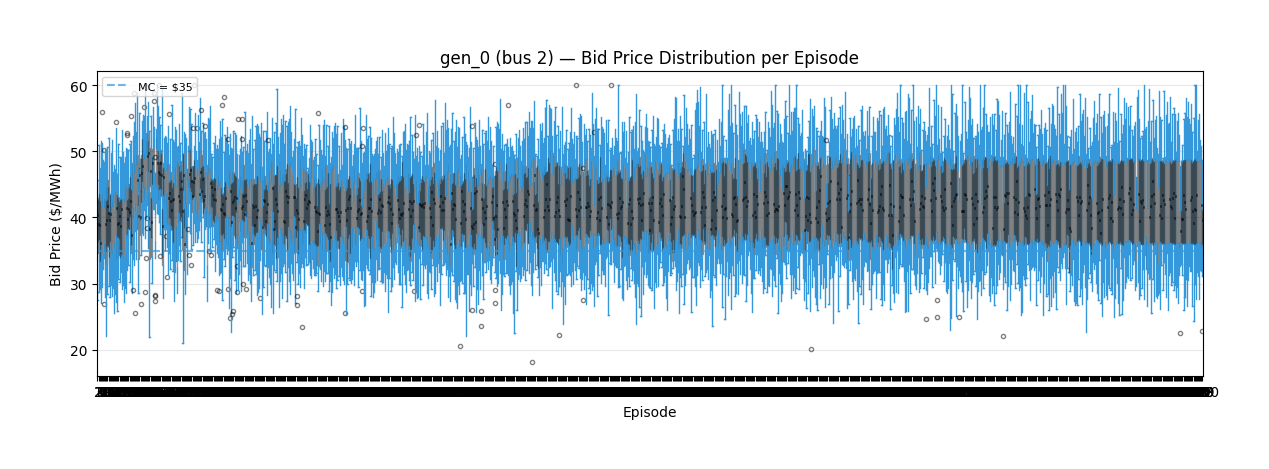

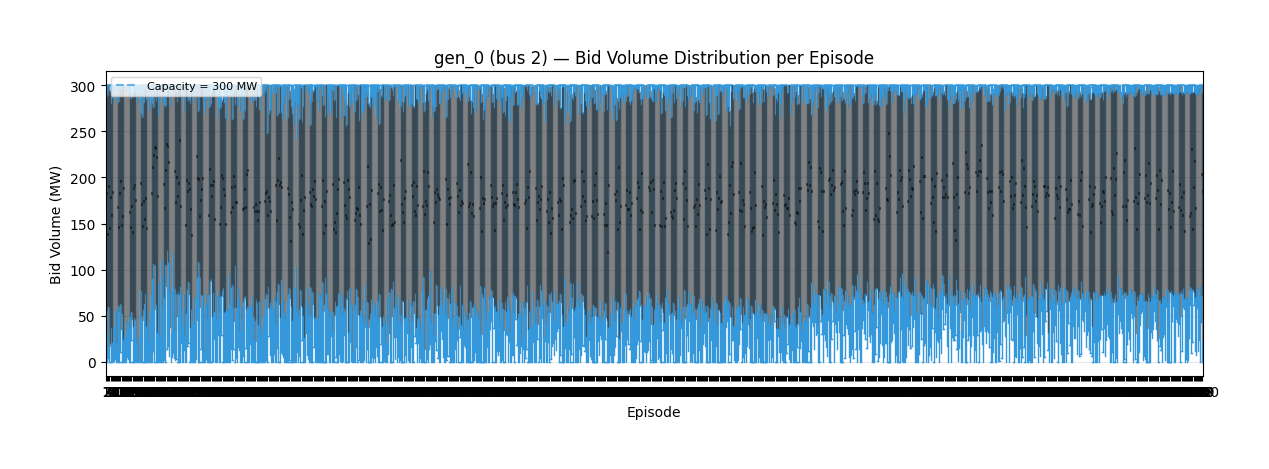

In [3]:
# Box plots of bid prices per episode (RL agents only)
fig, axes = plt.subplots(n_agents, 1, figsize=(12, 4 * n_agents), sharex=True, squeeze=False)
axes = axes.flatten()

for ax, unit in zip(axes, RL_AGENTS):
    unit_primary = primary_bids[primary_bids['unit_id'] == unit]
    eps = sorted(unit_primary['episode'].unique())

    data = [unit_primary[unit_primary['episode'] == ep]['bid_price'].values for ep in eps]

    bp = ax.boxplot(data, positions=eps, widths=0.6, patch_artist=True,
                     boxprops=dict(facecolor=UNIT_COLORS[unit], alpha=0.4),
                     medianprops=dict(color='black', linewidth=2),
                     whiskerprops=dict(color=UNIT_COLORS[unit]),
                     capprops=dict(color=UNIT_COLORS[unit]),
                     flierprops=dict(marker='o', markersize=3, alpha=0.5))

    ax.axhline(MC[unit], color=UNIT_COLORS[unit], linestyle='--', alpha=0.7,
               label=f'MC = ${MC[unit]:.0f}')
    ax.set_ylabel(f'{BID_LABEL} Price ($/MWh)')
    ax.set_title(f'{unit} (bus {gen_bus[unit]}) — {BID_LABEL} Price Distribution per Episode')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

axes[-1].set_xlabel('Episode')
plt.tight_layout()
plt.show()

# Box plots of bid volumes per episode (RL agents only)
fig2, axes2 = plt.subplots(n_agents, 1, figsize=(12, 4 * n_agents), sharex=True, squeeze=False)
axes2 = axes2.flatten()

for ax, unit in zip(axes2, RL_AGENTS):
    unit_primary = primary_bids[primary_bids['unit_id'] == unit]
    eps = sorted(unit_primary['episode'].unique())

    data = [unit_primary[unit_primary['episode'] == ep]['bid_volume'].values for ep in eps]

    bp = ax.boxplot(data, positions=eps, widths=0.6, patch_artist=True,
                     boxprops=dict(facecolor=UNIT_COLORS[unit], alpha=0.4),
                     medianprops=dict(color='black', linewidth=2),
                     whiskerprops=dict(color=UNIT_COLORS[unit]),
                     capprops=dict(color=UNIT_COLORS[unit]),
                     flierprops=dict(marker='o', markersize=3, alpha=0.5))

    ax.axhline(gen_capacity[unit], color=UNIT_COLORS[unit], linestyle='--', alpha=0.7,
               label=f'Capacity = {gen_capacity[unit]:.0f} MW')
    ax.set_ylabel(f'{BID_LABEL} Volume (MW)')
    ax.set_title(f'{unit} (bus {gen_bus[unit]}) — {BID_LABEL} Volume Distribution per Episode')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')

axes2[-1].set_xlabel('Episode')
plt.tight_layout()

## 3. Hourly Bid Profiles â€” Early vs Late Episodes

Compares bid prices by hour of day between first and last episode.
Shows whether agents learn time-of-day patterns (higher bids during peak hours).

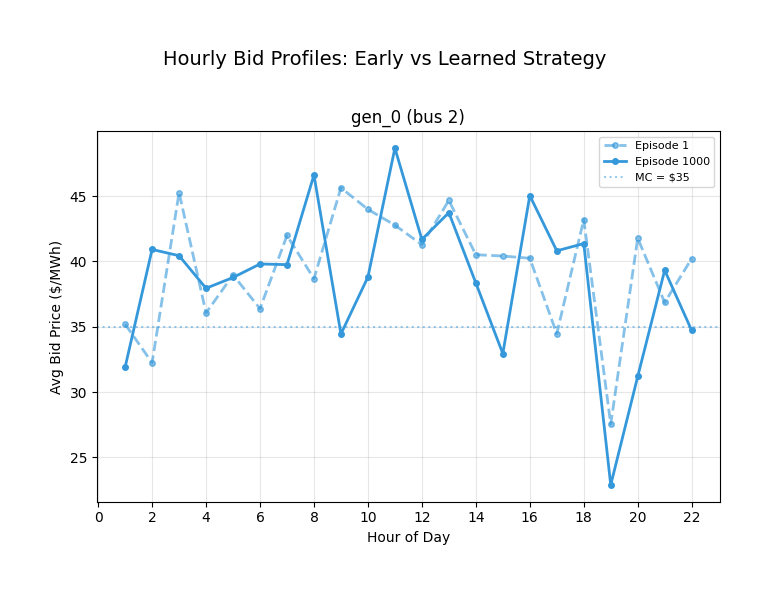

In [4]:
# Hourly bid profiles: first vs last episode (RL agents only)
first_ep = bids_df['episode'].min()
last_ep = bids_df['episode'].max()

fig, axes = plt.subplots(1, n_agents, figsize=(7 * n_agents, 5), sharey=True, squeeze=False)
axes = axes.flatten()

for ax, unit in zip(axes, RL_AGENTS):
    color = UNIT_COLORS[unit]
    for ep, style, alpha, label in [
        (first_ep, '--', 0.6, f'Episode {first_ep}'),
        (last_ep, '-', 1.0, f'Episode {last_ep}'),
    ]:
        ep_bids = primary_bids[(primary_bids['unit_id'] == unit) & (primary_bids['episode'] == ep)]
        hourly = ep_bids.groupby('hour')['bid_price'].mean()
        ax.plot(hourly.index, hourly.values, style, color=color, alpha=alpha,
                linewidth=2, marker='o', markersize=4, label=label)

    ax.axhline(MC[unit], color=color, linestyle=':', alpha=0.5, label=f'MC = ${MC[unit]:.0f}')
    ax.set_xlabel('Hour of Day')
    ax.set_ylabel(f'Avg {BID_LABEL} Price ($/MWh)')
    ax.set_title(f'{unit} (bus {gen_bus[unit]})')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(range(0, 24, 2))

fig.suptitle(f'Hourly {BID_LABEL} Profiles: Early vs Learned Strategy', fontsize=14, y=1.02)
plt.tight_layout()

## 4. Strategic Markup Summary

How much each agent marks up above marginal cost in the final episode.


Final episode (1000) strategy:
  gen_0: avg bid $38.6, MC $35, markup $3.6 (+10.4%), avg vol 164 MW

Final Policy (noise-free) â€” all hours:
Hour          Unit   Bid $/MWh   Volume MW   Markup %
----  ------------  ----------  ----------  ---------
   1         gen_0       36.06         291      +3.0%
   2         gen_0       36.06         291      +3.0%
   3         gen_0       36.01         291      +2.9%
   4         gen_0       36.00         292      +2.8%
   5         gen_0       36.16         292      +3.3%
   6         gen_0       36.36         292      +3.9%
   7         gen_0       48.45          64     +38.4%
   8         gen_0       48.65          70     +39.0%
   9         gen_0       48.80          75     +39.4%
  10         gen_0       48.91          79     +39.7%
  11         gen_0       48.97          81     +39.9%
  12         gen_0       48.99          82     +40.0%
  13         gen_0       48.97          81     +39.9%
  14         gen_0       48.91          79     

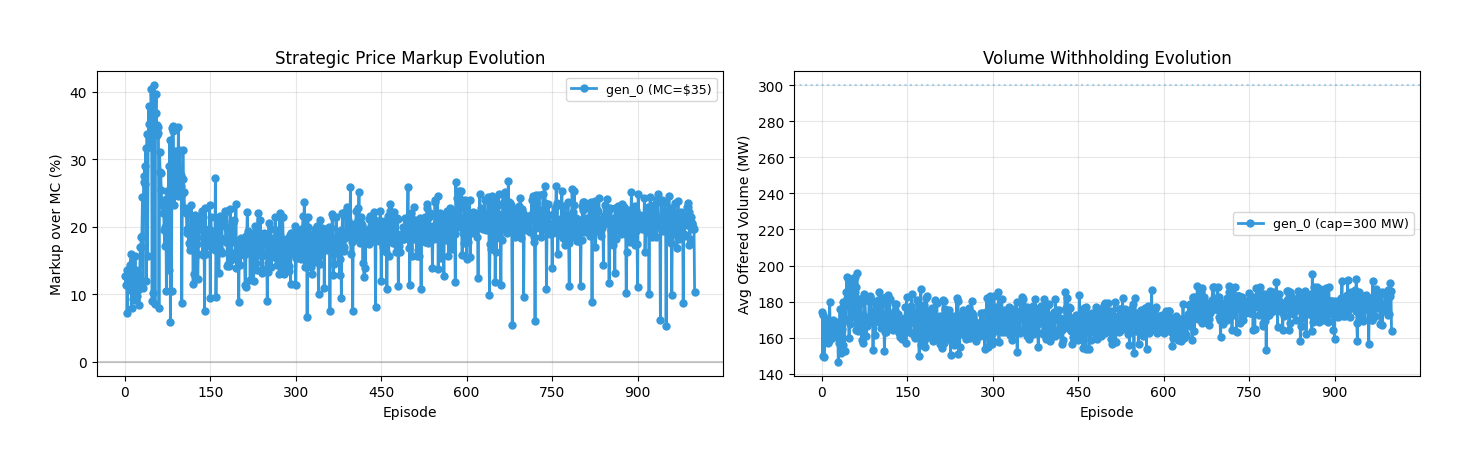

In [5]:
# Strategic markup: average bid vs MC in each episode
markup_records = []
for unit in RL_AGENTS:
    unit_primary = primary_bids[primary_bids['unit_id'] == unit]
    for ep in sorted(unit_primary['episode'].unique()):
        ep_data = unit_primary[unit_primary['episode'] == ep]
        avg_bid = ep_data['bid_price'].mean()
        avg_vol = ep_data['bid_volume'].mean()
        markup_records.append({
            'episode': ep, 'unit_id': unit,
            'avg_bid': avg_bid, 'avg_vol': avg_vol, 'mc': MC[unit],
            'markup': avg_bid - MC[unit],
            'markup_pct': 100 * (avg_bid - MC[unit]) / MC[unit],
        })

markup_df = pd.DataFrame(markup_records)

fig, axes_mk = plt.subplots(1, 2 if SINGLE_BID_MODE else 1,
                             figsize=(14 if SINGLE_BID_MODE else 10, 4))
if not isinstance(axes_mk, np.ndarray):
    axes_mk = [axes_mk]

# Left: price markup
ax = axes_mk[0]
for unit in RL_AGENTS:
    ud = markup_df[markup_df['unit_id'] == unit]
    ax.plot(ud['episode'], ud['markup_pct'], '-o', color=UNIT_COLORS[unit],
            linewidth=2, markersize=5, label=f'{unit} (MC=${MC[unit]:.0f})')

ax.axhline(0, color='gray', linestyle='-', alpha=0.4)
ax.set_xlabel('Episode')
ax.set_ylabel('Markup over MC (%)')
ax.set_title('Strategic Price Markup Evolution')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

# Right: volume offered (single-bid mode only)
if SINGLE_BID_MODE and len(axes_mk) > 1:
    ax2 = axes_mk[1]
    for unit in RL_AGENTS:
        ud = markup_df[markup_df['unit_id'] == unit]
        gen_row = _gen_df.loc[unit]
        p_max = float(gen_row['p_nom'])
        ax2.plot(ud['episode'], ud['avg_vol'], '-o', color=UNIT_COLORS[unit],
                linewidth=2, markersize=5, label=f'{unit} (cap={p_max:.0f} MW)')
        ax2.axhline(p_max, color=UNIT_COLORS[unit], linestyle=':', alpha=0.4)
    ax2.set_xlabel('Episode')
    ax2.set_ylabel('Avg Offered Volume (MW)')
    ax2.set_title('Volume Withholding Evolution')
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)
    ax2.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.tight_layout()

# Print final episode summary
final = markup_df[markup_df['episode'] == last_ep]
print(f'\nFinal episode ({last_ep}) strategy:')
for _, row in final.iterrows():
    vol_str = f', avg vol {row["avg_vol"]:.0f} MW' if SINGLE_BID_MODE else ''
    print(f'  {row["unit_id"]}: avg bid ${row["avg_bid"]:.1f}, MC ${row["mc"]:.0f}, '
          f'markup ${row["markup"]:.1f} ({row["markup_pct"]:+.1f}%){vol_str}')

# Print noise-free final policy bids for all hours
_fp_path = f'{RESULTS_DIR}/final_policy_bids.csv'
try:
    _fp_df = pd.read_csv(_fp_path, parse_dates=['timestamp'])
    _fp_df['hour'] = _fp_df['timestamp'].dt.hour
    print(f'\nFinal Policy (noise-free) â€” all hours:')
    print(f'{"Hour":>4}  {"Unit":>12}  {"Bid $/MWh":>10}  {"Volume MW":>10}  {"Markup %":>9}')
    print(f'{"-"*4}  {"-"*12}  {"-"*10}  {"-"*10}  {"-"*9}')
    for unit in RL_AGENTS:
        unit_fp = _fp_df[_fp_df['unit_id'] == unit].sort_values('hour')
        mc = MC[unit]
        for _, r in unit_fp.iterrows():
            markup_pct = 100 * (r['bid_price'] - mc) / mc
            print(f'{int(r["hour"]):4d}  {unit:>12}  {r["bid_price"]:10.2f}  {r["bid_volume"]:10.0f}  {markup_pct:+8.1f}%')
except FileNotFoundError:
    print(f'\nFinal policy bids not found â€” re-run training to generate.')

---

## 5. Final Evaluation â€” Best Learned Strategy in SCED

Identifies the best-performing episode **per agent for `PLOT_HOUR`** (highest individual
profit at that hour) and uses `FOCUS_AGENT`'s best episode for the SCED re-run and
nodal views.

The circlize shows: "what did the focus agent learn to bid at this hour, in its
best-performing instance of that hour?"

Set `FOCUS_AGENT` and `PLOT_HOUR` in the config cell to control the view.

In [6]:
# Identify the best episode PER AGENT PER HOUR â€” highest individual profit for PLOT_HOUR
# Profit = (LMP - MC) * dispatch for each RL unit at the selected hour.

results_path = f'{RESULTS_DIR}/results_history.csv'
results_df = pd.read_csv(results_path)
rl_results = results_df[results_df['is_rl'] == True].copy()

# MC from network (results_history.csv may have non-numeric marginal_cost in old runs)
rl_results['mc'] = rl_results['unit_id'].map(gen_mc)
rl_results['profit'] = (rl_results['accepted_price'] - rl_results['mc']) * rl_results['dispatch']

# --- Load final policy bids (noise-free) ---
_policy_bids_path = f'{RESULTS_DIR}/final_policy_bids.csv'
try:
    final_policy_bids = pd.read_csv(_policy_bids_path, parse_dates=['timestamp'])
    final_policy_bids['hour'] = final_policy_bids['timestamp'].dt.hour
    # Use bid_type from CSV directly (single/pmin/flex); backwards compat same as above
    fp_types = set(final_policy_bids['bid_type'].unique())
    if fp_types == {'pmin'}:
        final_policy_bids['bid_type'] = 'single'
    print(f'Loaded final policy bids: {len(final_policy_bids)} rows')
except FileNotFoundError:
    final_policy_bids = None
    print(f'Final policy bids not found â€” re-run training to generate.')

# --- Hour-level stats (for best-episode selection) ---
hour_results = rl_results[rl_results['hour'] == PLOT_HOUR].copy()

hour_unit_ep = hour_results.groupby(['episode', 'unit_id']).agg(
    lmp=('accepted_price', 'first'),
    dispatch=('dispatch', 'sum'),
    profit=('profit', 'sum'),
).round(1)

# Add bid price from bid_history for this hour (use primary_bids)
hour_primary = primary_bids[primary_bids['hour'] == PLOT_HOUR]
hour_primary_ep = hour_primary.groupby(['episode', 'unit_id']).agg(
    bid=('bid_price', 'mean'),
    vol=('bid_volume', 'mean'),
).round(1)
hour_unit_ep = hour_unit_ep.join(hour_primary_ep)

# Best episode per agent for PLOT_HOUR
best_ep_hour = {}
for unit in RL_AGENTS:
    unit_h = hour_unit_ep.xs(unit, level='unit_id')
    best_ep_hour[unit] = unit_h['profit'].idxmax()

best_ep = best_ep_hour[FOCUS_AGENT]

print(f'\nBest episode per agent at hour {PLOT_HOUR} (highest profit):')
for unit, ep in best_ep_hour.items():
    profit = hour_unit_ep.loc[(ep, unit), 'profit']
    focus_marker = ' <-- FOCUS' if unit == FOCUS_AGENT else ''
    print(f'  {unit}: episode {ep} (profit ${profit:,.0f}){focus_marker}')
print()

# Build hour-level summary table: one row per episode
rows = []
for ep in sorted(hour_results['episode'].unique()):
    row = {'episode': ep}
    for unit in RL_AGENTS:
        if (ep, unit) in hour_unit_ep.index:
            s = hour_unit_ep.loc[(ep, unit)]
            row[f'{unit} bid$'] = s['bid']
            if SINGLE_BID_MODE:
                row[f'{unit} vol'] = s['vol']
            row[f'{unit} LMP$'] = s['lmp']
            row[f'{unit} MW'] = s['dispatch']
            row[f'{unit} profit$'] = s['profit']
    best_markers = [u for u in RL_AGENTS if best_ep_hour[u] == ep]
    row[''] = ', '.join(f'<-- best {u}' for u in best_markers) if best_markers else ''
    rows.append(row)

ep_summary = pd.DataFrame(rows).set_index('episode')

print(f'Hour {PLOT_HOUR} â€” per-agent bid, LMP, dispatch, and profit by episode:')
ep_summary.round(1)

Loaded final policy bids: 22 rows

Best episode per agent at hour 12 (highest profit):
  gen_0: episode 24 (profit $974) <-- FOCUS

Hour 12 â€” per-agent bid, LMP, dispatch, and profit by episode:


,gen_0 bid$,gen_0 vol,gen_0 LMP$,gen_0 MW,gen_0 profit$,
episode,,,,,,
1,41.3,55.0,50.0,55.0,824.8,
2,45.2,72.2,45.2,65.0,664.9,
3,45.4,7.0,50.0,7.0,104.5,
4,34.7,2.8,50.0,2.8,42.3,
5,36.2,112.9,36.2,65.0,80.7,
...,...,...,...,...,...,...
996,52.9,72.5,50.0,0.0,0.0,
997,48.8,102.9,48.8,65.0,895.7,
998,45.4,102.6,45.4,65.0,675.3,


## 4b. Optimization Landscape â€” Reward Surface Over Action Space

Shows the reward gen_0 can earn at every point in its 2D action space:
**X = bid price**, **Y = volume fraction** (0 = offer nothing, 1 = offer full 300 MW).

Three columns per row:
1. **Profit** â€” revenue minus operating cost. Two symmetric ridges: physical withholding (low vol, low price) and economic withholding (high price, any vol â‰¥ residual demand).
2. **Equilibrium Penalty** â€” sum of idle penalty (discourages physical withholding) and markup penalty (discourages economic withholding). Zero at the competitive equilibrium (â˜…).
3. **Net Reward** â€” profit minus penalty, normalized. This is what the agent actually optimizes.

The **grey dashed horizontal line** marks the volume fraction equal to residual demand Ã· max_power â€” below this the agent can't cover all demand alone, so gen_1 becomes marginal (LMP jumps to \$50). The **orange vertical line** marks gen_1's MC (\$50) â€” bids above this get gen_0 pushed out of merit order.

Scatter points = actual agent bids during training (colour = episode number, blueâ†’pink = earlyâ†’late).
Red âœ• = **final policy bid** (noise-free, from `final_policy_bids.csv`).

> **Note:** This uses a simplified merit-order model (no transmission constraints). In the actual SCED, nodal congestion can shift LMPs bus-by-bus, making the real surface more complex.
>
> **Run order:** Run Section 5 first to get `final_policy_bids` overlay, or this cell loads it from CSV automatically if training has already completed.

Wavelet params: scale=100.0, vol_scale=300.0, price_width=2.0, vol_width=5.0
MC mountain: scale=100.0, sigma=3.0, tau=0.5
Guard params: vol_guard(penalty=50.0, steep=0.03), price_guard(penalty=30.0, steep=0.05)
Peak hours: [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17] | Off-peak hours: [0, 1, 2, 3, 4, 5, 6, 18, 19, 20, 21, 22, 23]
Peak residuals: 9-65 MW
Training bids: 22000 rows, 1000 episodes
Surface hours: [12, 17, 1, 6]
  H12: PEAK, demand=315 MW, residual=65 MW, cf=$50
  H17: PEAK, demand=259 MW, residual=9 MW, cf=$50
  H01: OFF-PEAK, demand=158 MW, residual=0 MW, cf=$20
  H06: OFF-PEAK, demand=237 MW, residual=0 MW, cf=$20


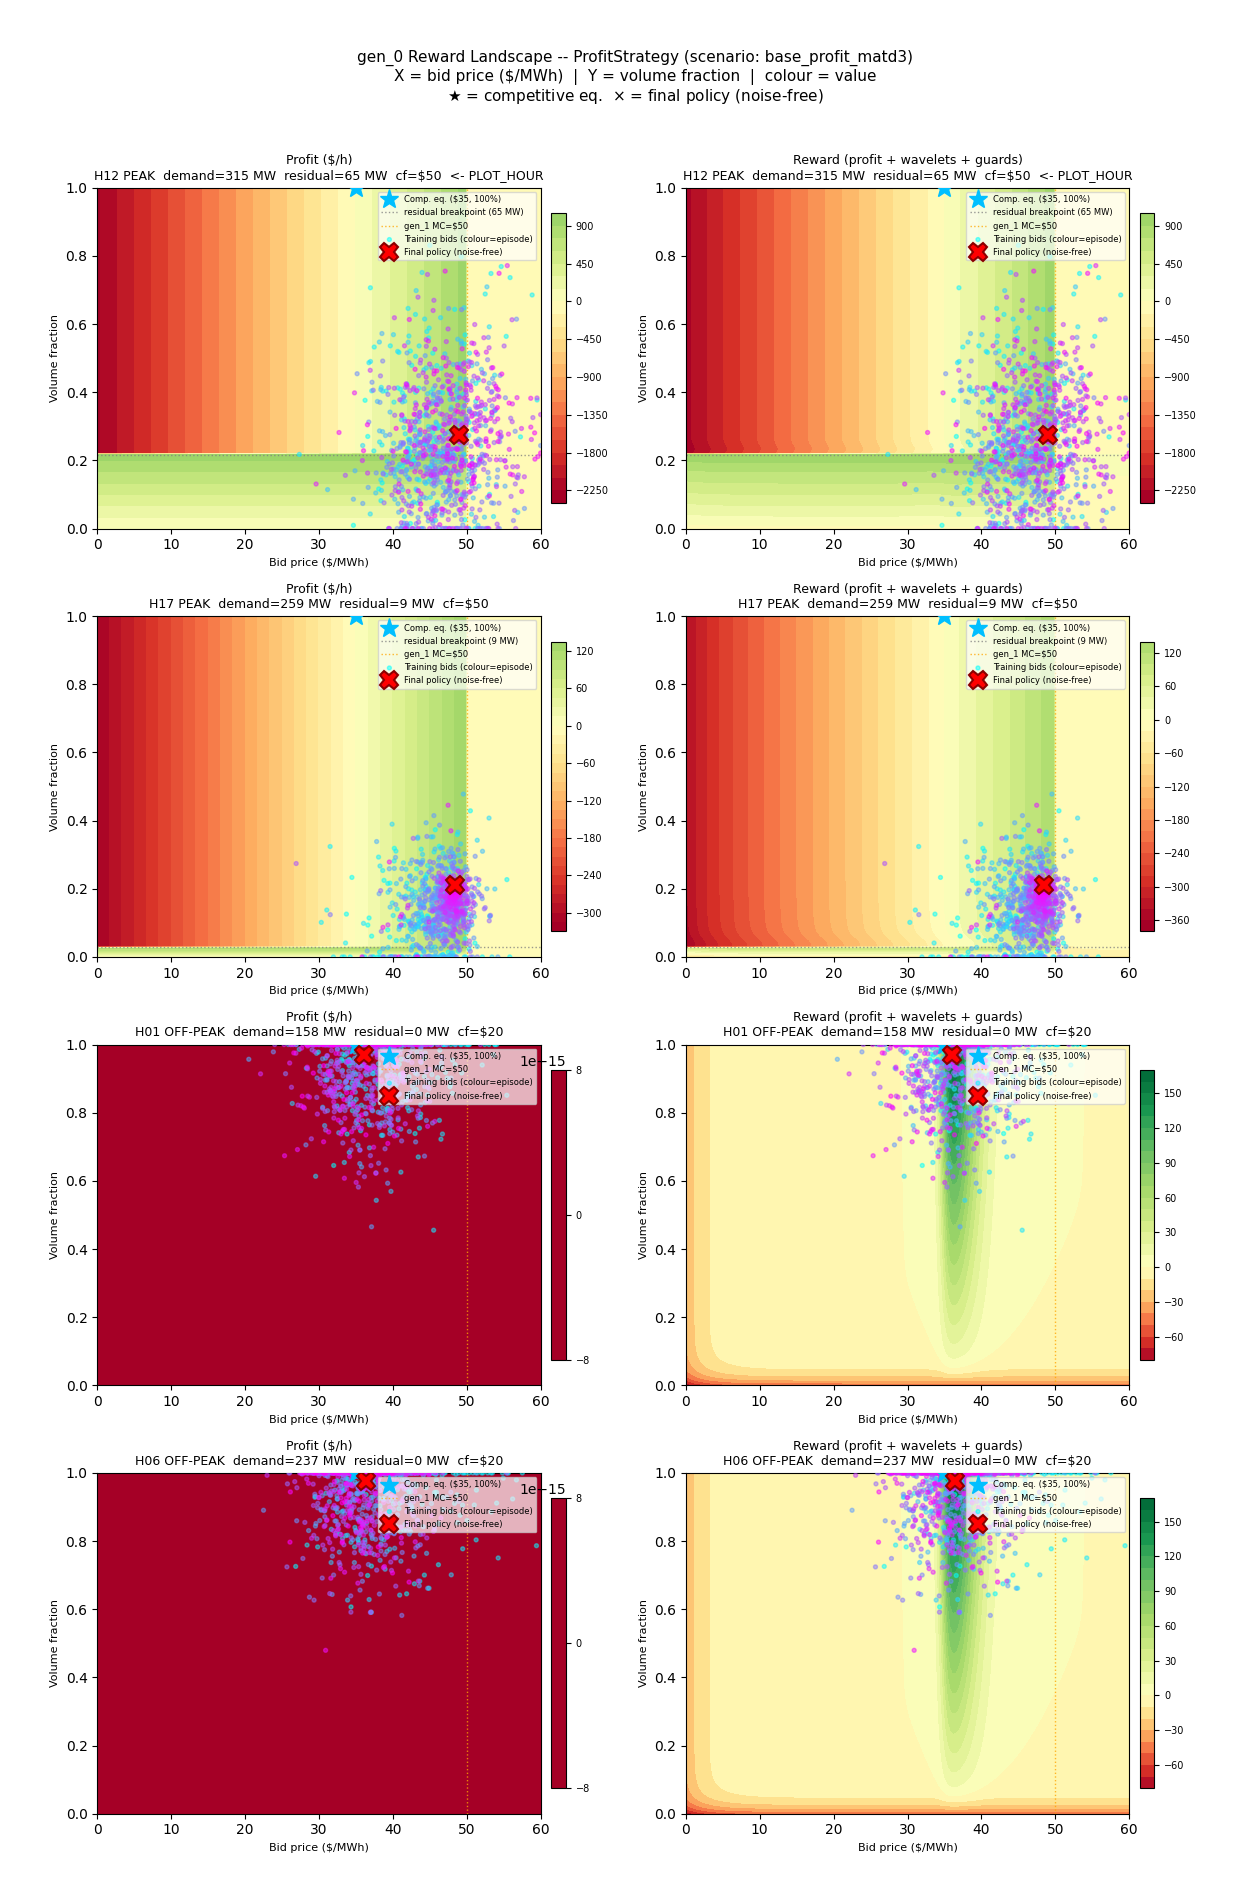


H12 (PEAK, residual=65 MW, cf=$50):
  Comp. eq.  ($35, 100%): reward=-1.9  profit=$-2
  At comp MC ($50, vf=22%): reward=+1.7  profit=$0
  Optimal: ($47.9, vf=22%): reward=+987.7  profit=$972
  Final policy: $49.0/MWh x 82 MW (vol_frac=0.27)

H17 (PEAK, residual=9 MW, cf=$50):
  Comp. eq.  ($35, 100%): reward=-0.3  profit=$-0
  At comp MC ($50, vf=3%): reward=-18.5  profit=$0
  Optimal: ($49.7, vf=100%): reward=+133.1  profit=$133
  Final policy: $48.4/MWh x 64 MW (vol_frac=0.21)

H01 (OFF-PEAK, residual=0 MW, cf=$20):
  Comp. eq.  ($35, 100%): reward=+97.5  profit=$-0
  At comp MC ($50, vf=0%): reward=-50.0  profit=$-0
  Optimal: ($36.2, vf=100%): reward=+169.1  profit=$-0
  Final policy: $36.1/MWh x 291 MW (vol_frac=0.97)

H06 (OFF-PEAK, residual=0 MW, cf=$20):
  Comp. eq.  ($35, 100%): reward=+97.5  profit=$-0
  At comp MC ($50, vf=0%): reward=-50.0  profit=$-0
  Optimal: ($36.2, vf=100%): reward=+169.1  profit=$-0
  Final policy: $36.4/MWh x 292 MW (vol_frac=0.97)


In [7]:
# ── Analytical reward surface over the 2D action space ───────────────────────
#
# ProfitStrategy reward function:
#   reward = profit + wavelet_shaping + mc_mountain(off-peak) + guards
#
# Shows 2 off-peak + 2 on-peak hours.

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import yaml, os, pandas as pd

# ── Parameters from scenarios.yaml ───────────────────────────────────────────
with open('scenarios.yaml') as _f:
    _scen = yaml.safe_load(_f)[SCENARIO]

_pr  = _scen['profile']
_g0  = _scen['generators']['gen_0']
_g1  = _scen['generators']['gen_1']
_gs  = _scen['generators']['gen_slack_0']
_tr  = _scen['training']
_lc  = _tr.get('learning_config', {})

MC_0      = float(_g0['price'])
MC_1      = float(_g1['price'])
P_MAX_0   = float(_g0['p_max'])
P_MAX_1   = float(_g1['p_max'])
P_MAX_S   = float(_gs['p_max'])
PRICE_CAP = float(_g0.get('price_cap', float(_tr.get('max_bid_price', 100.0))))
BASE_LOAD = 90 + 100 + 125  # MW

# ── Terrain shaping parameters (Ricker wavelets) ────────────────────────────
WAVELET_SCALE       = float(_lc.get('wavelet_scale', 100.0))
VOL_WAVELET_SCALE   = float(_lc.get('vol_wavelet_scale', 300.0))
PRICE_WAVELET_WIDTH = float(_lc.get('price_wavelet_width', 2.0))
VOL_WAVELET_WIDTH   = float(_lc.get('vol_wavelet_width', 5.0))
MC_MOUNTAIN_SCALE   = float(_lc.get('mc_mountain_scale', 300.0))
MC_MOUNTAIN_SIGMA   = float(_lc.get('mc_mountain_sigma', 3.0))
MC_MOUNTAIN_TAU     = float(_lc.get('mc_mountain_tau', 0.5))

# ── Guard parameters ─────────────────────────────────────────────────────────
VOL_PENALTY     = float(_lc.get('vol_penalty', 50.0))
VOL_STEEPNESS   = float(_lc.get('vol_steepness', 0.03))
PRICE_PENALTY   = float(_lc.get('price_penalty', 30.0))
PRICE_STEEPNESS = float(_lc.get('price_steepness', 0.05))
DURATION        = 1.0  # hours per product

print(f"Wavelet params: scale={WAVELET_SCALE}, vol_scale={VOL_WAVELET_SCALE}, "
      f"price_width={PRICE_WAVELET_WIDTH}, vol_width={VOL_WAVELET_WIDTH}")
print(f"MC mountain: scale={MC_MOUNTAIN_SCALE}, sigma={MC_MOUNTAIN_SIGMA}, tau={MC_MOUNTAIN_TAU}")
print(f"Guard params: vol_guard(penalty={VOL_PENALTY}, steep={VOL_STEEPNESS}), "
      f"price_guard(penalty={PRICE_PENALTY}, steep={PRICE_STEEPNESS})")

# ── Demand profile ────────────────────────────────────────────────────────────
_t = np.arange(24)
_raw = _pr['base'] + _pr['amplitude'] * np.sin(
    2 * np.pi * (_t - _pr['phase_shift']) / _pr['period'])
_profile  = np.clip(_raw, _pr['clip_min'], _pr['clip_max'])
_demand   = BASE_LOAD * _profile
_residual = np.maximum(0.0, _demand - P_MAX_S)

_counterfactual = np.where(_residual > 0.01, MC_1, 20.0)
_peak_hours = np.where(_counterfactual >= MC_0)[0]
_offpeak_hours = np.where(_counterfactual < MC_0)[0]
print(f"Peak hours: {_peak_hours.tolist()} | Off-peak hours: {_offpeak_hours.tolist()}")
if len(_peak_hours) > 0:
    print(f"Peak residuals: {_residual[_peak_hours].min():.0f}-{_residual[_peak_hours].max():.0f} MW")

# ── Grid ──────────────────────────────────────────────────────────────────────
N = 200
price_ax = np.linspace(0.0, PRICE_CAP, N)
vol_ax   = np.linspace(0.0, 1.0, N)
PP, VV   = np.meshgrid(price_ax, vol_ax)
BID_VOL  = VV * P_MAX_0

def _reward_surface(hour):
    """Compute profit and reward surfaces matching ProfitStrategy reward."""
    D   = float(_demand[hour])
    res = max(0.0, D - P_MAX_S)
    cf  = float(_counterfactual[hour])

    # ── SCED dispatch model ───────────────────────────────────────
    dispatched_vol = np.zeros_like(PP)
    lmp = np.full_like(PP, 20.0)

    if res > 0.01:
        A = PP <= MC_1
        A_marginal = A & (BID_VOL >= res)
        A_partial  = A & (BID_VOL < res)
        B = ~A
        B_needed = B & (res > P_MAX_1)
        B_dispatched_vol = np.minimum(BID_VOL, res - P_MAX_1)

        dispatched_vol = np.where(A_marginal, res, dispatched_vol)
        dispatched_vol = np.where(A_partial, BID_VOL, dispatched_vol)
        dispatched_vol = np.where(B_needed, np.maximum(0.0, B_dispatched_vol), dispatched_vol)

        lmp = np.where(A_marginal, PP, lmp)
        lmp = np.where(A_partial, MC_1, lmp)
        lmp = np.where(B_needed & (B_dispatched_vol > 0.01), PP, lmp)
        lmp = np.where(B & ~B_needed, MC_1, lmp)

    # ── Profit ────────────────────────────────────────────────────
    profit = (lmp - MC_0) * dispatched_vol * DURATION

    # ── Fractions ─────────────────────────────────────────────────
    vol_frac   = BID_VOL / max(P_MAX_0, 1.0)
    price_frac = PP / max(PRICE_CAP, 1.0)

    # ── Terrain shaping (Ricker wavelets) ────────────────────────
    mc_mountain = np.zeros_like(PP)
    pw = max(PRICE_WAVELET_WIDTH, 0.01)
    shaping = np.zeros_like(PP)

    if res > 0.01:
        # PEAK: Ricker wavelets at all three edges
        resid_frac = min(res / P_MAX_0, 1.0)
        w_scale = WAVELET_SCALE * resid_frac

        # 1. Price ceiling wavelet — approach competitor MC from below
        #    No vol_frac scaling — price edges matter at all volume levels
        delta_ceil = (cf - PP) / pw
        price_ceil_w = w_scale * delta_ceil * np.exp(-0.5 * delta_ceil**2)

        # 2. MC floor wavelet — stay above own MC
        delta_mc = (PP - MC_0) / pw
        mc_floor_w = w_scale * delta_mc * np.exp(-0.5 * delta_mc**2)

        # 3. Volume wavelet — approach residual demand from below
        vw = max(VOL_WAVELET_WIDTH, 0.01)
        delta_vol = (res - BID_VOL) / vw
        vw_scale = VOL_WAVELET_SCALE * resid_frac
        vol_w = vw_scale * delta_vol * np.exp(-0.5 * delta_vol**2)

        shaping = price_ceil_w + mc_floor_w + vol_w
    else:
        # OFF-PEAK: MC mountain only (Gaussian safe harbor)
        sigma = max(MC_MOUNTAIN_SIGMA, 0.01)
        tau   = max(MC_MOUNTAIN_TAU, 0.01)
        mc_floor = 1.0 / (1.0 + np.exp(-(PP - MC_0) / tau))
        mc_decay = np.exp(-np.maximum(PP - MC_0, 0.0)**2 / (2.0 * sigma**2))
        mc_mountain = 2.0 * MC_MOUNTAIN_SCALE * mc_floor * mc_decay * vol_frac
        shaping = mc_mountain

    # ── Guardrails ────────────────────────────────────────────────
    vol_guard = -VOL_PENALTY * np.exp(-vol_frac / max(VOL_STEEPNESS, 1e-6))
    price_guard = -PRICE_PENALTY * np.exp(-price_frac / max(PRICE_STEEPNESS, 1e-6))

    # ── Total reward ──────────────────────────────────────────────
    reward = profit + shaping + vol_guard + price_guard

    return profit, reward

# ── Training bids ─────────────────────────────────────────────────────────────
_bids_df = None
try:
    if bids_df is not None and len(bids_df) > 0:
        _bids_df = bids_df.copy()
except NameError:
    pass
if _bids_df is None and os.path.exists(f'{RESULTS_DIR}/bid_history.csv'):
    _bids_df = pd.read_csv(f'{RESULTS_DIR}/bid_history.csv')
    if 'hour' not in _bids_df.columns:
        _bids_df['hour'] = pd.to_datetime(_bids_df['timestamp']).dt.hour
if _bids_df is not None:
    print(f"Training bids: {len(_bids_df)} rows, {_bids_df['episode'].nunique()} episodes")

# ── Final policy bids (noise-free) ───────────────────────────────────────────
_fp_df = None
try:
    if final_policy_bids is not None and len(final_policy_bids) > 0:
        _fp_df = final_policy_bids.copy()
        if 'hour' not in _fp_df.columns:
            _fp_df['hour'] = _fp_df['timestamp'].dt.hour
except NameError:
    pass
if _fp_df is None:
    _fp_path = f'{RESULTS_DIR}/final_policy_bids.csv'
    if os.path.exists(_fp_path):
        _fp_df = pd.read_csv(_fp_path, parse_dates=['timestamp'])
        _fp_df['hour'] = _fp_df['timestamp'].dt.hour

# ── Surface hours: 2 off-peak + 2 on-peak ────────────────────────────────────
_offpeak_picks = []
if len(_offpeak_hours) >= 2:
    _offpeak_picks = [int(_offpeak_hours[1]), int(_offpeak_hours[len(_offpeak_hours)//2])]
elif len(_offpeak_hours) == 1:
    _offpeak_picks = [int(_offpeak_hours[0])]

_peak_picks = []
if len(_peak_hours) >= 2:
    _peak_picks = [int(_peak_hours[len(_peak_hours)//2]),
                   int(_peak_hours[-1])]
elif len(_peak_hours) == 1:
    _peak_picks = [int(_peak_hours[0])]

SURFACE_HOURS = []
for h in _peak_picks + _offpeak_picks:
    if h not in SURFACE_HOURS:
        SURFACE_HOURS.append(h)
if PLOT_HOUR not in SURFACE_HOURS:
    SURFACE_HOURS.insert(0, PLOT_HOUR)
SURFACE_HOURS = SURFACE_HOURS[:4]

print(f"Surface hours: {SURFACE_HOURS}")
for h in SURFACE_HOURS:
    res = max(0, _demand[h] - P_MAX_S)
    regime = "PEAK" if _counterfactual[h] >= MC_0 else "OFF-PEAK"
    print(f"  H{h:02d}: {regime}, demand={_demand[h]:.0f} MW, residual={res:.0f} MW, cf=${_counterfactual[h]:.0f}")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(len(SURFACE_HOURS), 2, figsize=(12, 4.5 * len(SURFACE_HOURS)))
if len(SURFACE_HOURS) == 1:
    axes = axes[np.newaxis, :]
fig.suptitle(
    f'gen_0 Reward Landscape -- ProfitStrategy (scenario: {SCENARIO})\n'
    f'X = bid price ($/MWh)  |  Y = volume fraction  |  colour = value\n'
    r'$\bigstar$ = competitive eq.  $\times$ = final policy (noise-free)',
    fontsize=11, y=1.01
)

_fp_plotted = set()

for row, h in enumerate(SURFACE_HOURS):
    profit, reward = _reward_surface(h)
    res      = max(0.0, float(_demand[h]) - P_MAX_S)
    vf_break = res / P_MAX_0 if P_MAX_0 > 0 else 0.0
    cf       = float(_counterfactual[h])
    regime   = "PEAK" if cf >= MC_0 else "OFF-PEAK"
    hlabel   = f'H{h:02d} {regime}  demand={_demand[h]:.0f} MW  residual={res:.0f} MW  cf=${cf:.0f}'
    ph_tag   = '  <- PLOT_HOUR' if h == PLOT_HOUR else ''

    for col, (data, cmap, title) in enumerate([
        (profit, 'RdYlGn', f'Profit ($/h)\n{hlabel}{ph_tag}'),
        (reward, 'RdYlGn', f'Reward (profit + wavelets + guards)\n{hlabel}{ph_tag}'),
    ]):
        ax   = axes[row, col]
        vmax = max(float(np.abs(data).max()), 0.01)
        vmin_val = float(data.min())

        if vmin_val < -0.01:
            norm = mcolors.TwoSlopeNorm(vmin=vmin_val, vcenter=0.0, vmax=vmax)
            im = ax.contourf(price_ax, vol_ax, data, levels=30, cmap=cmap, norm=norm)
        else:
            im = ax.contourf(price_ax, vol_ax, data, levels=30, cmap=cmap,
                             vmin=0, vmax=vmax)

        fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02).ax.tick_params(labelsize=7)
        ax.set_title(title, fontsize=9)
        ax.set_xlabel('Bid price ($/MWh)', fontsize=8)
        ax.set_ylabel('Volume fraction',   fontsize=8)

        ax.plot(MC_0, 1.0, '*', color='deepskyblue', markersize=14, zorder=6,
                label=f'Comp. eq. (${MC_0:.0f}, 100%)')
        if vf_break > 0.01:
            ax.axhline(vf_break, color='gray', lw=1, ls=':', alpha=0.8,
                       label=f'residual breakpoint ({res:.0f} MW)')
        ax.axvline(MC_1, color='orange', lw=1, ls=':', alpha=0.8,
                   label=f'gen_1 MC=${MC_1:.0f}')

        if _bids_df is not None:
            _hb = _bids_df[(_bids_df['hour'] == h) & (_bids_df['unit_id'] == FOCUS_AGENT)]
            if len(_hb) > 0:
                ax.scatter(
                    _hb['bid_price'], _hb['bid_volume'] / P_MAX_0,
                    c=_hb['episode'], cmap='cool', s=8, alpha=0.5, zorder=5,
                    label='Training bids (colour=episode)'
                )

        if _fp_df is not None:
            _fp_h = _fp_df[(_fp_df['hour'] == h) & (_fp_df['unit_id'] == FOCUS_AGENT)]
            for _, _fp_bid in _fp_h.iterrows():
                _fp_label = 'Final policy (noise-free)' if (h, col) not in _fp_plotted else '_nolegend_'
                _fp_plotted.add((h, col))
                ax.plot(
                    _fp_bid['bid_price'], _fp_bid['bid_volume'] / P_MAX_0,
                    'X', color='red', markersize=13, zorder=8,
                    markeredgecolor='darkred', markeredgewidth=1.5,
                    label=_fp_label
                )

        ax.legend(fontsize=6, loc='upper right', framealpha=0.7)

plt.tight_layout()
plt.show()

# ── Numerical summary ─────────────────────────────────────────────────────────
for h in SURFACE_HOURS:
    _p, _r = _reward_surface(h)
    res = max(0, _demand[h] - P_MAX_S)
    cf  = float(_counterfactual[h])
    regime = "PEAK" if cf >= MC_0 else "OFF-PEAK"
    print(f"\nH{h:02d} ({regime}, residual={res:.0f} MW, cf=${cf:.0f}):")
    i_mc = int(round(MC_0 / PRICE_CAP * (N - 1)))
    print(f"  Comp. eq.  (${MC_0:.0f}, 100%): reward={_r[N-1, i_mc]:+.1f}  profit=${_p[N-1, i_mc]:.0f}")
    i_comp = min(int(round(MC_1 / PRICE_CAP * (N - 1))), N-1)
    vf_res = res / P_MAX_0 if P_MAX_0 > 0 else 0
    i_res  = max(0, min(N-1, int(round(vf_res * (N - 1)))))
    print(f"  At comp MC (${MC_1:.0f}, vf={vf_res:.0%}): reward={_r[i_res, i_comp]:+.1f}  profit=${_p[i_res, i_comp]:.0f}")
    opt_idx = np.unravel_index(np.argmax(_r), _r.shape)
    opt_price = price_ax[opt_idx[1]]
    opt_vf    = vol_ax[opt_idx[0]]
    print(f"  Optimal: (${opt_price:.1f}, vf={opt_vf:.0%}): reward={_r[opt_idx]:+.1f}  profit=${_p[opt_idx]:.0f}")

    if _fp_df is not None:
        _fp_h = _fp_df[(_fp_df['hour'] == h) & (_fp_df['unit_id'] == FOCUS_AGENT)]
        for _, b in _fp_h.iterrows():
            print(f"  Final policy: ${b['bid_price']:.1f}/MWh x {b['bid_volume']:.0f} MW "
                  f"(vol_frac={b['bid_volume']/P_MAX_0:.2f})")

### Clearing Price, Dispatch, and Nodal Views â€” Final Learned Policy

Re-runs SCED with the **noise-free final policy bids** from `final_policy_bids.csv`.
This shows what the network actually dispatches, flows, and prices when the RL agents
apply their learned strategy without exploration noise.

In [8]:
# â”€â”€ SCED Re-run Setup: profile variables + network + orderbook + clear â”€â”€â”€â”€â”€â”€â”€â”€
# Defines the variables needed by subsequent cells:
#   periods, base, amplitude, phase_shift, period_len, clip_min, clip_max
#   network, accepted, rejected, meta, flows, market_products

from datetime import timedelta, datetime as _dt
from ieee9_network import build_ieee9_network
from clearing.sced_clearing import clear_sced
from learning_runner import _apply_generator_overrides, _apply_line_overrides

# â”€â”€ Profile variables (from scenarios.yaml) â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
_pcfg      = scenario_cfg.get('profile', {})
periods    = scenario_cfg.get('periods', 24)
base        = _pcfg.get('base',        0.6)
amplitude   = _pcfg.get('amplitude',   0.4)
phase_shift = _pcfg.get('phase_shift', 4)
period_len  = _pcfg.get('period',      32)
clip_min    = _pcfg.get('clip_min',    0.5)
clip_max    = _pcfg.get('clip_max',    1.0)

# â”€â”€ Build network with scenario overrides â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
_network_rerun = build_ieee9_network(start='2025-01-01', periods=periods, profile_cfg=_pcfg)
_apply_generator_overrides(_network_rerun, scenario_cfg.get('generators', {}))
_apply_line_overrides(_network_rerun, line_overrides)

# Expose as 'network' for nodal plot helpers (compute_ptdf_flows, assign_bus_colors, etc.)
network = _network_rerun

_gen_df_rerun  = network.generators.copy()
_gen_df_rerun.rename(columns={'bus': 'node', 'p_nom': 'max_power'}, inplace=True)
_loads_df_rerun = network.loads.copy()
_loads_df_rerun.rename(columns={'bus': 'node', 'p_set': 'min_power'}, inplace=True)

grid_data_rerun = {
    'buses':      network.buses,
    'lines':      network.lines,
    'generators': _gen_df_rerun,
    'loads':      _loads_df_rerun,
}

# â”€â”€ Build orderbook â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
# RL agents â†’ final policy bids (noise-free); non-RL generators â†’ MC at full capacity
if final_policy_bids is None:
    print('WARNING: final_policy_bids is None â€” RL agents will bid at MC (no strategic bids).')

_orderbook_rerun = []
market_products  = []

for _i, _ts in enumerate(network.snapshots):
    _start = _ts.to_pydatetime()
    _end   = _start + timedelta(hours=1)
    market_products.append((_start, _end, None))

    for _gen_name, _gen in _gen_df_rerun.iterrows():
        if final_policy_bids is not None and _gen_name in RL_GENERATORS:
            _h = _ts.hour
            _fp = final_policy_bids[
                (final_policy_bids['unit_id'] == _gen_name) &
                (final_policy_bids['hour'] == _h)
            ]
            if not _fp.empty:
                _bid_price = float(_fp.iloc[0]['bid_price'])
                _bid_vol   = float(_fp.iloc[0]['bid_volume'])
            else:
                _bid_price = float(_gen['marginal_cost'])
                _bid_vol   = float(_gen['max_power'])
        else:
            _bid_price = float(_gen['marginal_cost'])
            _bid_vol   = float(_gen['max_power'])

        _orderbook_rerun.append({
            'start_time': _start,
            'end_time':   _end,
            'only_hours': None,
            'price':      _bid_price,
            'volume':     _bid_vol,
            'node':       _gen['node'],
            'unit_id':    _gen_name,
            'bid_id':     f'{_gen_name}_{_i}',
        })

    # Demand bids (inelastic, high willingness-to-pay)
    for _load_name in network.loads.index:
        if _load_name in network.loads_t.p_set.columns:
            _demand = float(network.loads_t.p_set.at[_ts, _load_name])
        else:
            _demand = float(_loads_df_rerun.at[_load_name, 'min_power'])
        _orderbook_rerun.append({
            'start_time': _start,
            'end_time':   _end,
            'only_hours': None,
            'price':      1000.0,
            'volume':     -_demand,
            'node':       network.loads.at[_load_name, 'bus'],
            'unit_id':    _load_name,
            'bid_id':     f'{_load_name}_{_i}',
        })

# â”€â”€ Run SCED â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€â”€
print(f'Running SCED re-run ({len(_orderbook_rerun)} orders, {len(market_products)} periods)...')
accepted, rejected, meta, flows = clear_sced(
    _orderbook_rerun, market_products, grid_data_rerun, solver='highs',
)
print(f'SCED complete â€” accepted: {len(accepted)}, rejected: {len(rejected)}')

Unsupported features include: three-winding transformers, switches, in_service status, shunt impedances and tap positions of transformers.
INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines
INFO:learning_runner:Added generator 'gen_peaker_0': bus=1, p_max=50.0, price=60.0
INFO:learning_runner:Generator overrides applied: gen_0($35, 300MW), gen_1($50, 270MW), gen_slack_0($20, 250MW), gen_peaker_0($60, 50MW)
INFO:learning_runner:Line overrides applied: line_0(250MW), line_1(250MW), line_2(150MW), line_3(300MW), line_4(150MW), line_5(250MW), line_6(250MW), line_7(250MW), line_8(250MW)
Running SCED re-run (168 orders, 24 periods)...
INFO:clearing.sced_clearing:Solving Egret SCED (relaxed=True)...
Calculating PTDF Matrix Factorization
INFO:egret:Calculating PTDF Matrix Factorization
Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP has 1119 rows; 1032 cols; 2060 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 6e+03]
  Cost    [1e+0

In [9]:
load_profile = np.array([
    np.clip(base + amplitude * np.sin(2 * np.pi * (h - phase_shift) / period_len), clip_min, clip_max)
    for h in range(periods)
])

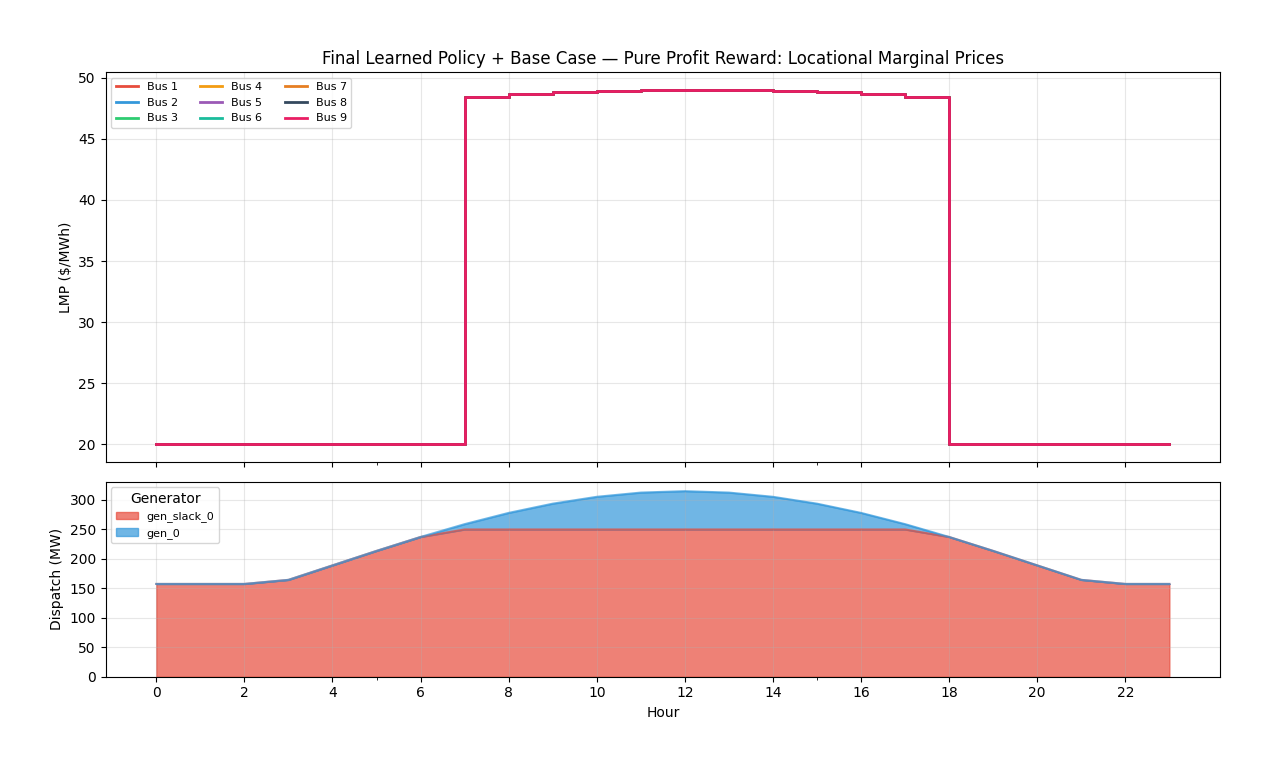

In [10]:
# LMP and dispatch from SCED re-run with final policy bids
acc_df_best = pd.DataFrame(accepted)
acc_df_best['hour'] = acc_df_best['start_time'].dt.hour

# Build LMP pivot from meta (always has all buses, even zero-dispatch ones)
lmp_records = []
for m in meta:
    hour = m['product_start'].hour
    for bus, lmp in m.get('bus_lmps', {}).items():
        lmp_records.append({'hour': hour, 'bus': bus, 'lmp': lmp})
lmp_final = pd.DataFrame(lmp_records).drop_duplicates(subset=['hour', 'bus'])
lmp_pivot = lmp_final.pivot(index='hour', columns='bus', values='lmp').sort_index()

# All network buses (for coloring transit vs active buses)
all_buses = sorted(_network_rerun.buses.index.tolist(), key=lambda x: int(x))
# Active buses (those with LMPs in SCED output)
active_buses = sorted([str(b) for b in lmp_pivot.columns.tolist()], key=lambda x: int(x))
palette_idx = 0
bus_color_map = {}
for b in all_buses:
    if b in active_buses:
        bus_color_map[b] = BUS_PALETTE[palette_idx % len(BUS_PALETTE)]
        palette_idx += 1
    else:
        bus_color_map[b] = TRANSIT_COLOR

# --- Dual panel: LMP + dispatch ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                                gridspec_kw={'height_ratios': [2, 1]})

# Top: LMP per bus
for bus in active_buses:
    if bus in lmp_pivot.columns:
        ax1.step(lmp_pivot.index, lmp_pivot[bus], where='post',
                 label=f'Bus {bus}', color=bus_color_map[bus], linewidth=2)

ax1.set_ylabel('LMP ($/MWh)')
ax1.set_title(f'Final Learned Policy + {scenario_name}: Locational Marginal Prices')
ax1.legend(loc='upper left', fontsize=8, ncol=3)
ax1.grid(True, alpha=0.3)

# Bottom: dispatch stacked area
supply_acc = acc_df_best[acc_df_best['volume'] > 0].copy()
disp_pivot = supply_acc.pivot_table(
    index='hour', columns='unit_id', values='accepted_volume',
    aggfunc='sum', fill_value=0,
)

gen_order = sorted(gen_mc.keys(), key=lambda g: gen_mc[g])
cols = [c for c in gen_order if c in disp_pivot.columns]
gen_colors = {g: bus_color_map.get(gen_bus[g], '#888') for g in gen_order}

disp_pivot[cols].plot.area(ax=ax2, alpha=0.7, color=[gen_colors[c] for c in cols])
ax2.set_ylabel('Dispatch (MW)')
ax2.set_xlabel('Hour')
ax2.legend(title='Generator', loc='upper left', fontsize=8)
ax2.set_xticks(range(0, 24, 2))
ax2.grid(True, alpha=0.3)

plt.tight_layout()

In [11]:
# plot_hour function â€” uses scenario name in titles
def get_hour_data(hour_idx):
    """Extract supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps for a given hour."""
    t_start = market_products[hour_idx][0]

    # Build nameplate capacity lookup (network gens + scenario-only gens)
    _capacities = dict(gen_capacity)  # from setup cell
    for sg_name, sg in scenario_cfg.get('generators', {}).items():
        if sg_name not in _capacities:
            _capacities[sg_name] = sg.get('p_max', 0)

    supply_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] <= 0:
            continue
        bus = o['node']
        if bus not in supply_by_bus:
            supply_by_bus[bus] = []
        supply_by_bus[bus].append({
            'unit_id': o['unit_id'],
            'price': o['price'],
            'volume': o['volume'],  # bid volume
            'accepted_volume': o.get('accepted_volume', 0),
            'capacity': _capacities.get(o['unit_id'], o['volume']),  # nameplate
        })

    # Ensure ALL generators appear even if they didn't bid or bid 0 volume.
    # This guarantees every generator's nameplate capacity bar is visible.
    all_gen_names = set(_gen_df.index) | set(scenario_cfg.get('generators', {}).keys())
    for gn in all_gen_names:
        bus = gen_bus.get(gn)
        if not bus:
            continue
        if bus not in supply_by_bus:
            supply_by_bus[bus] = []
        existing = {g['unit_id'] for g in supply_by_bus[bus]}
        if gn not in existing:
            supply_by_bus[bus].append({
                'unit_id': gn,
                'price': gen_mc.get(gn, 0),
                'volume': 0,
                'accepted_volume': 0,
                'capacity': _capacities.get(gn, 0),
            })

    for bus in supply_by_bus:
        supply_by_bus[bus].sort(key=lambda g: g['price'])

    demand_by_bus = {}
    demand_served_by_bus = {}
    for o in accepted + rejected:
        if o['start_time'] != t_start or o['volume'] >= 0:
            continue
        bus = o['node']
        demand_by_bus[bus] = demand_by_bus.get(bus, 0) + abs(o['volume'])
        demand_served_by_bus[bus] = demand_served_by_bus.get(bus, 0) + abs(o.get('accepted_volume', 0))

    # Get bus LMPs from meta (always available for ALL buses, even zero-dispatch ones)
    bus_lmps = meta[hour_idx].get('bus_lmps', {})

    hour_line_flows = {}
    for (line_name, t_idx), flow_mw in flows.items():
        if t_idx == hour_idx:
            hour_line_flows[line_name] = flow_mw

    return supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows


def plot_hour(hour_idx):
    """Plot circlize + network topology for a given hour."""
    supply_by_bus, demand_by_bus, demand_served_by_bus, bus_lmps, hour_line_flows = get_hour_data(hour_idx)
    t_start = market_products[hour_idx][0]

    colors = assign_bus_colors(all_buses, supply_by_bus, demand_by_bus)
    flow_list = compute_ptdf_flows(network, supply_by_bus, demand_by_bus)

    m = meta[hour_idx]
    avg_lmp = m['price']

    fig_circ = plot_nodal_circlize(
        supply_by_bus, demand_by_bus, all_buses,
        flows=flow_list,
        clearing_price=avg_lmp,
        bus_lmps=bus_lmps,
        title=f'Final Policy + {scenario_name} â€” Hour {hour_idx:02d} ({t_start.strftime("%Y-%m-%d %H:%M")})',
        bus_colors=colors,
        gen_marginal_costs=gen_mc,
    )

    fig_topo, ax_topo = plot_network_topology(
        network, supply_by_bus, demand_by_bus,
        bus_colors=colors,
        bus_lmps=bus_lmps,
        demand_served_by_bus=demand_served_by_bus,
        line_flows=hour_line_flows if hour_line_flows else None,
        title=f'Final Policy + {scenario_name} â€” Hour {hour_idx:02d} (Avg LMP: ${avg_lmp:.0f}/MWh)',
    )

    plt.show()

    # Print summary
    print(f'\nHour {hour_idx:02d} Summary ({scenario_name}, Final Policy):')
    print(f'  Total demand: {m["demand_volume"]:.1f} MW')
    print(f'  Total supply: {m["supply_volume"]:.1f} MW')
    print(f'  Avg LMP: ${avg_lmp:.2f}/MWh  (range: ${m["min_price"]:.2f} - ${m["max_price"]:.2f})')
    print(f'  Bus LMPs: {bus_lmps}')
    print(f'  Dispatch:')
    for bus, gens in sorted(supply_by_bus.items()):
        for g in gens:
            if g['accepted_volume'] > 0.1:
                nameplate = g.get('capacity', g['volume'])
                mc_str = f' (MC=${gen_mc.get(g["unit_id"], 0):.0f})' if g['unit_id'] in gen_mc else ''
                print(f'    {g["unit_id"]} (bus {bus}): '
                      f'{g["accepted_volume"]:.1f}/{nameplate:.0f} MW '
                      f'[bid: ${g["price"]:.1f} Ã— {g["volume"]:.0f} MW]{mc_str}')
    if hour_line_flows:
        print(f'  Line flows:')
        for ln, fl in sorted(hour_line_flows.items()):
            row = network.lines.loc[ln]
            s_nom = network.lines.at[ln, 's_nom']
            direction = f"{row['bus0']}->{row['bus1']}" if fl >= 0 else f"{row['bus1']}->{row['bus0']}"
            constrained = ' *CONGESTED*' if abs(fl) >= 0.95 * s_nom else ''
            print(f'    {ln} ({direction}): {abs(fl):.1f}/{s_nom:.0f} MW{constrained}')

print('plot_hour() ready â€” call plot_hour(PLOT_HOUR) below')

plot_hour() ready â€” call plot_hour(PLOT_HOUR) below


### Single-Hour Bid Evolution Across Episodes

Shows how each generator's bids (price and volume) for the selected hour (`PLOT_HOUR`)
evolve across training episodes. In single-bid mode, both price and volume are shown.
Non-RL generators are included as flat reference lines.

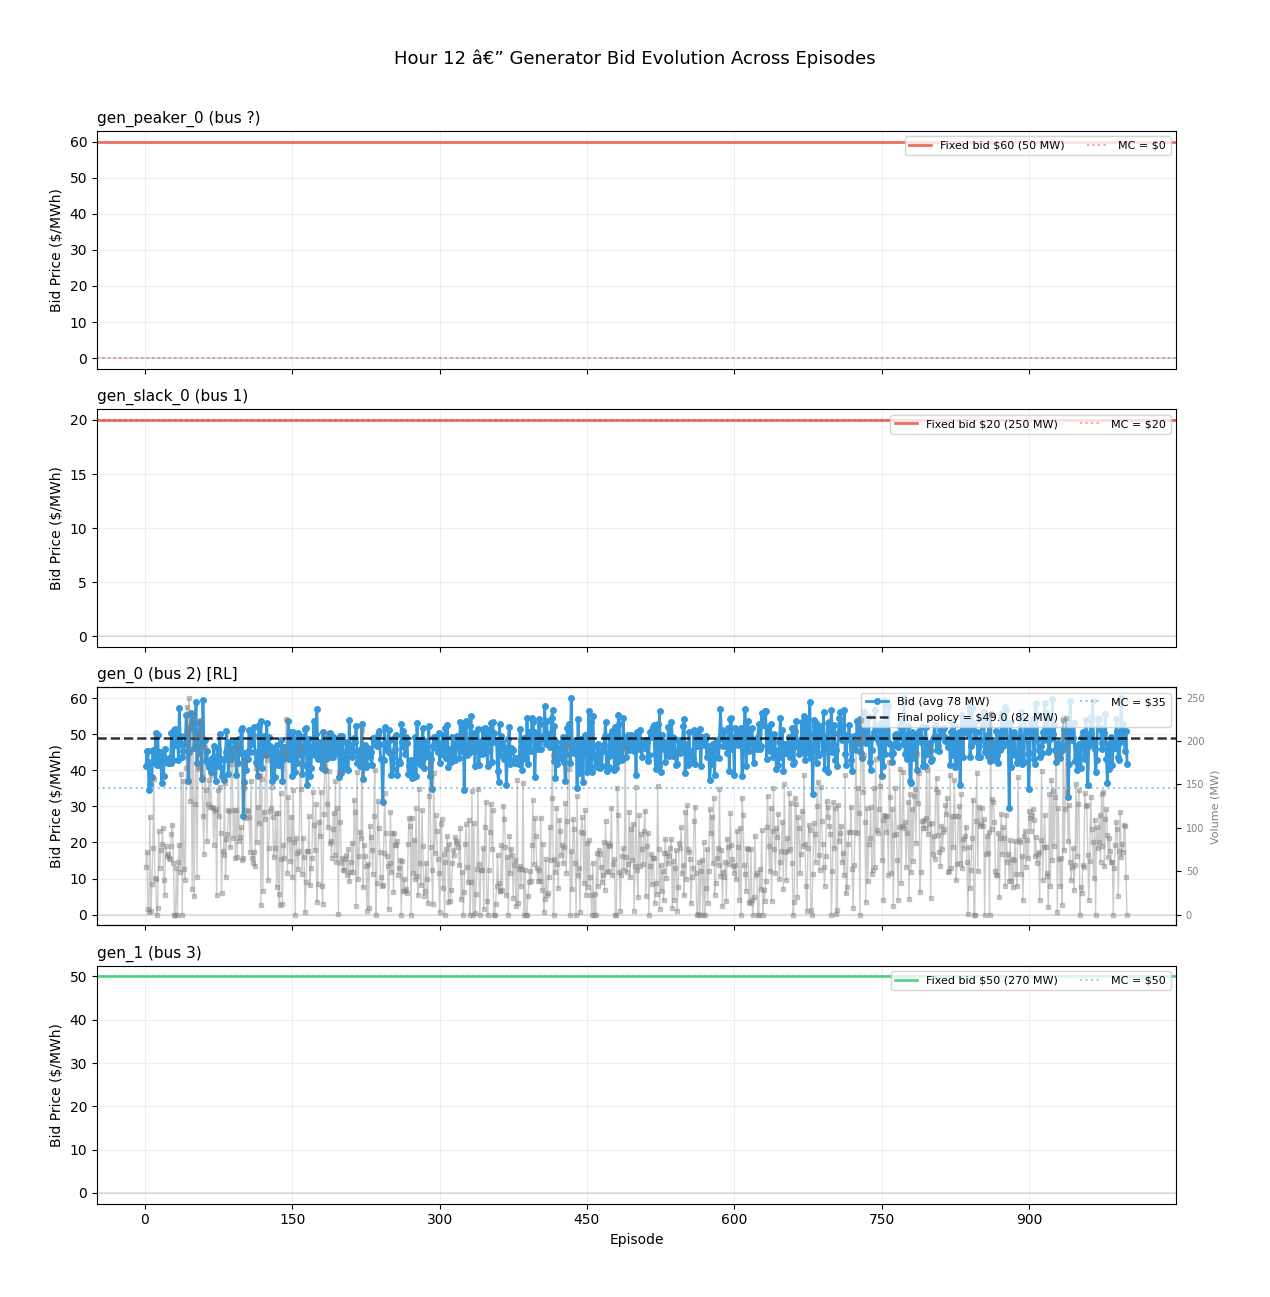

In [12]:
# Single-hour bid evolution: all generators for PLOT_HOUR across episodes
# Shows price (and volume for single-bid mode) evolution for RL agents
# Reference lines: dotted = MC, dashed = final policy bid (noise-free)

# Derived from scenario config (used for non-RL generator metadata)
scenario_gens  = scenario_cfg.get('generators', {})
non_rl_gens    = [g for g in gen_mc if g not in RL_GENERATORS]

hour_bids = bids_df[bids_df['hour'] == PLOT_HOUR].copy()
episodes = sorted(hour_bids['episode'].unique())

# Pre-compute final policy bid price per RL agent at PLOT_HOUR
final_policy_price = {}
final_policy_vol = {}
if final_policy_bids is not None:
    fp_hour = final_policy_bids[final_policy_bids['hour'] == PLOT_HOUR]
    for unit_id in RL_AGENTS:
        unit_fp = fp_hour[fp_hour['unit_id'] == unit_id]
        if len(unit_fp) > 0:
            final_policy_price[unit_id] = unit_fp['bid_price'].mean()
            final_policy_vol[unit_id] = unit_fp['bid_volume'].mean()

# All generators that bid in this hour (RL from bid_history; non-RL from scenario)
all_gens_in_hour = sorted(set(hour_bids['unit_id'].unique()) | set(non_rl_gens))
# Also include scenario-only gens (e.g., gen_peaker_0)
for sg_name in scenario_gens:
    if sg_name not in all_gens_in_hour:
        all_gens_in_hour.append(sg_name)
all_gens_in_hour = sorted(all_gens_in_hour, key=lambda g: gen_mc.get(g, 0))

n_gens = len(all_gens_in_hour)

fig, axes = plt.subplots(n_gens, 1, figsize=(12, 3 * n_gens), sharex=True)
if n_gens == 1:
    axes = [axes]

for ax, gen_name in zip(axes, all_gens_in_hour):
    mc_val = gen_mc.get(gen_name, 0)
    bus = gen_bus.get(gen_name, '?')
    bus_idx = sorted(set(gen_bus.values()), key=lambda x: int(x)).index(bus) if bus in gen_bus.values() else 0
    color = BUS_PALETTE[bus_idx % len(BUS_PALETTE)]

    if gen_name in RL_GENERATORS:
        gen_hour = hour_bids[hour_bids['unit_id'] == gen_name]

        # Price evolution (primary signal)
        ep_data = gen_hour.groupby('episode').agg(
            price_mean=('bid_price', 'mean'),
            price_min=('bid_price', 'min'),
            price_max=('bid_price', 'max'),
            vol_mean=('bid_volume', 'mean'),
        )
        ax.fill_between(ep_data.index, ep_data['price_min'], ep_data['price_max'],
                        alpha=0.12, color=color)
        ax.plot(ep_data.index, ep_data['price_mean'], '-o', color=color,
                linewidth=2, markersize=4,
                label=f'{BID_LABEL} (avg {ep_data["vol_mean"].mean():.0f} MW)')

        # Volume on secondary y-axis
        ax2 = ax.twinx()
        ax2.plot(ep_data.index, ep_data['vol_mean'], '-s', color='gray',
                 alpha=0.4, linewidth=1, markersize=3)
        ax2.set_ylabel('Volume (MW)', color='gray', fontsize=8)
        ax2.tick_params(axis='y', labelcolor='gray', labelsize=7)

        # Final policy bid reference (dashed, slightly thicker)
        if gen_name in final_policy_price:
            fp_price = final_policy_price[gen_name]
            fp_vol = final_policy_vol.get(gen_name, 0)
            ax.axhline(fp_price, color='black', linestyle='--', linewidth=1.8,
                       alpha=0.8, label=f'Final policy = ${fp_price:.1f} ({fp_vol:.0f} MW)')

    else:
        # Non-RL generator: flat line at MC with capacity annotation
        sg = scenario_gens.get(gen_name, {})
        price = sg.get('price', mc_val)
        cap = sg.get('p_max', float(_gen_df.loc[gen_name, 'p_nom']) if gen_name in _gen_df.index else 0)
        ax.axhline(price, color=color, linewidth=2, alpha=0.8,
                   label=f'Fixed bid ${price:.0f} ({cap:.0f} MW)')

    # MC reference (dotted)
    ax.axhline(mc_val, color=color, linestyle=':', alpha=0.5, linewidth=1.5,
               label=f'MC = ${mc_val:.0f}')
    ax.axhline(0, color='gray', linestyle='-', alpha=0.2)

    ax.set_ylabel(f'{BID_LABEL} Price ($/MWh)')
    rl_tag = ' [RL]' if gen_name in RL_GENERATORS else ''
    ax.set_title(f'{gen_name} (bus {bus}){rl_tag}', fontsize=11, loc='left')
    ax.legend(loc='upper right', fontsize=8, ncol=2)
    ax.grid(True, alpha=0.2)

axes[-1].set_xlabel('Episode')
axes[-1].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
fig.suptitle(f'Hour {PLOT_HOUR} â€” Generator {BID_LABEL} Evolution Across Episodes',
             fontsize=13, y=1.01)
plt.tight_layout()

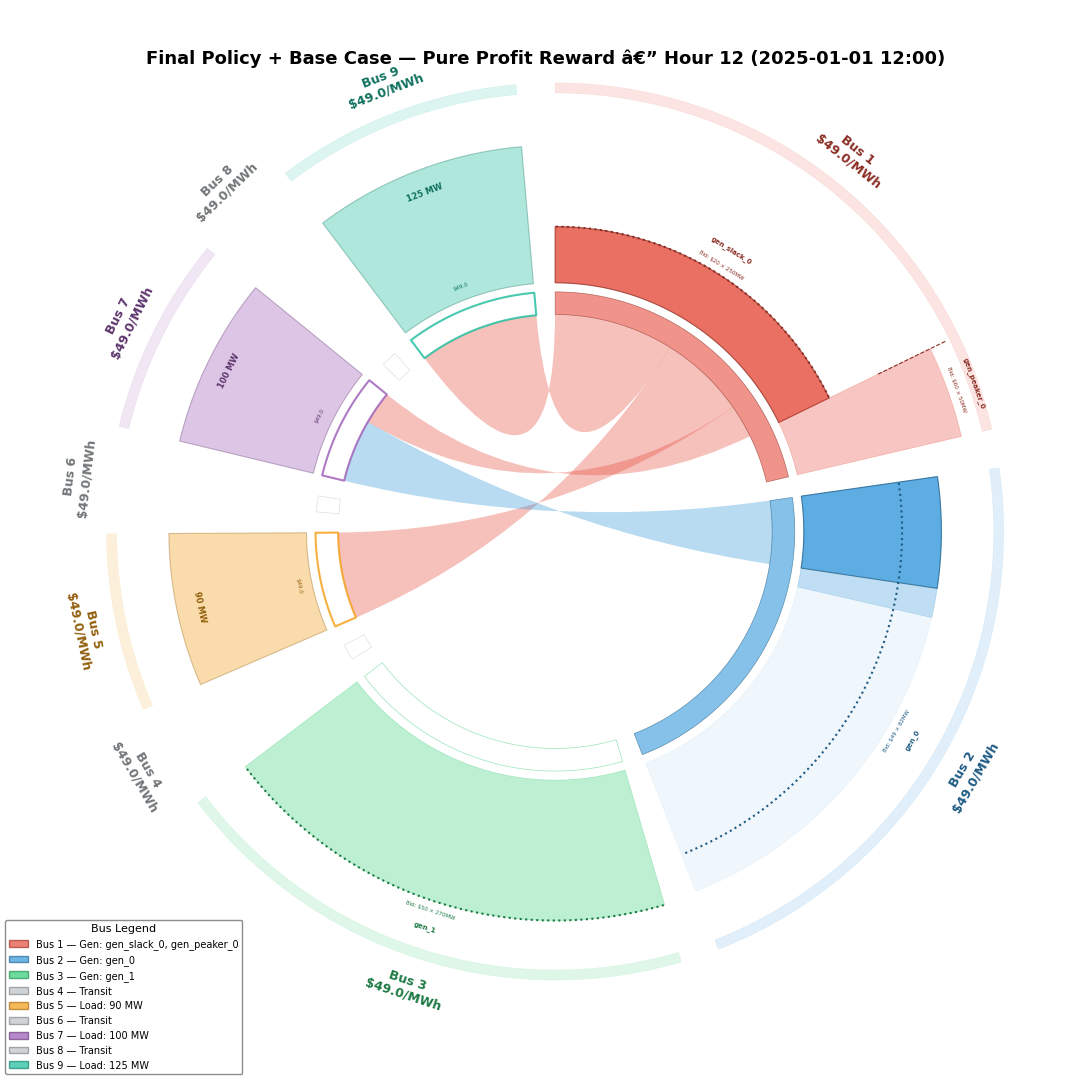

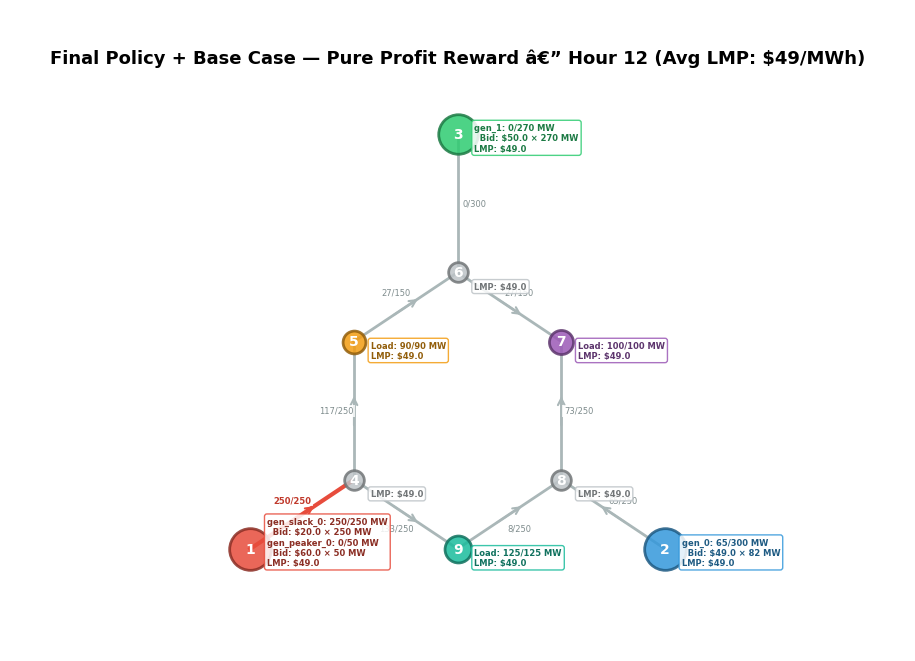


Hour 12 Summary (Base Case — Pure Profit Reward, Final Policy):
  Total demand: 315.0 MW
  Total supply: 315.0 MW
  Avg LMP: $48.99/MWh  (range: $48.99 - $48.99)
  Bus LMPs: {'1': 48.99139881134033, '2': 48.99139881134033, '3': 48.99139881134033, '4': 48.99139881134033, '5': 48.99139881134033, '6': 48.99139881134033, '7': 48.99139881134033, '8': 48.99139881134033, '9': 48.99139881134033}
  Dispatch:
    gen_slack_0 (bus 1): 250.0/250 MW [bid: $20.0 Ã— 250 MW] (MC=$20)
    gen_0 (bus 2): 65.0/300 MW [bid: $49.0 Ã— 82 MW] (MC=$35)
  Line flows:
    line_0 (1->4): 250.0/250 MW *CONGESTED*
    line_1 (4->5): 116.7/250 MW
    line_2 (5->6): 26.7/150 MW
    line_3 (3->6): 0.0/300 MW
    line_4 (6->7): 26.7/150 MW
    line_5 (8->7): 73.3/250 MW
    line_6 (2->8): 65.0/250 MW
    line_7 (9->8): 8.3/250 MW
    line_8 (4->9): 133.3/250 MW


In [13]:
plot_hour(PLOT_HOUR)

### Generator Economics â€” Learned vs Competitive

Compares revenue under learned (strategic) bidding vs what would happen at marginal cost.
RL agents earn markup revenue when their bids set or influence LMPs above MC.

In [14]:
# Generator economics from SCED-cleared results (final policy, noise-free)
supply_acc = acc_df_best[acc_df_best['volume'] > 0].copy()
supply_acc['revenue'] = supply_acc['accepted_price'] * supply_acc['accepted_volume']
supply_acc['cost'] = supply_acc['unit_id'].map(gen_mc) * supply_acc['accepted_volume']

econ = supply_acc.groupby('unit_id').agg(
    total_dispatch_MWh=('accepted_volume', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_cost=('cost', 'sum'),
).round(2)
econ['profit'] = econ['total_revenue'] - econ['total_cost']
econ['avg_lmp'] = (econ['total_revenue'] / econ['total_dispatch_MWh']).round(2)
econ['avg_bid'] = supply_acc.groupby('unit_id')['price'].mean().round(2)
econ['mc'] = econ.index.map(gen_mc)
econ['is_rl'] = econ.index.isin(RL_GENERATORS)

print(f'Generator Economics (24h, Final Learned Policy â€” No Noise):')
print('  * = RL agent\n')
econ

Generator Economics (24h, Final Learned Policy â€” No Noise):
  * = RL agent



,total_dispatch_MWh,total_revenue,total_cost,profit,avg_lmp,avg_bid,mc,is_rl
unit_id,,,,,,,,
gen_0,462.70,22610.94,16194.52,6416.42,48.87,48.78,35.0,True
gen_slack_0,5145.94,182055.76,102918.72,79137.04,35.38,20.00,20.0,False


### Order Details â€” Selected Hour

In [15]:
# Show all accepted orders for the selected hour (final learned policy)
t = market_products[PLOT_HOUR][0]
hour_acc = acc_df_best[acc_df_best['start_time'] == t].copy()

# Add RL indicator and MC for comparison
hour_acc['is_rl'] = hour_acc['unit_id'].isin(RL_GENERATORS)
hour_acc['mc'] = hour_acc['unit_id'].map(gen_mc)

print(f'Hour {PLOT_HOUR} â€” Accepted Orders (Final Learned Policy, No Noise):')
print('  * = RL agent bid\n')
hour_acc[['unit_id', 'node', 'price', 'volume', 'accepted_price', 'accepted_volume', 'mc', 'is_rl']].sort_values('price')

Hour 12 â€” Accepted Orders (Final Learned Policy, No Noise):
  * = RL agent bid



,unit_id,node,price,volume,accepted_price,accepted_volume,mc,is_rl
54,gen_slack_0,1,20.000000,250.000000,48.991399,250.0,20.0,False
53,gen_0,2,48.991399,82.232791,48.991399,65.0,35.0,True
55,load_0,5,1000.000000,-90.000000,48.991399,-90.0,NaN,False
56,load_1,7,1000.000000,-100.000000,48.991399,-100.0,NaN,False
57,load_2,9,1000.000000,-125.000000,48.991399,-125.0,NaN,False


---

### Final Policy Inference â€” Noise-Free Evaluation

After training, the learning runner runs one additional episode using the final policy
with **no exploration noise** (evaluation mode). This shows the deterministic output
of the trained network under real simulation conditions.

Files: `final_policy_bids.csv` (bids) and `final_policy_results.csv` (LMPs, dispatch).

In [16]:
# Load noise-free final policy bids and results
policy_bids_path = f'{RESULTS_DIR}/final_policy_bids.csv'
policy_results_path = f'{RESULTS_DIR}/final_policy_results.csv'

try:
    policy_bids = pd.read_csv(policy_bids_path, parse_dates=['timestamp'])
    policy_results = pd.read_csv(policy_results_path)
except FileNotFoundError:
    print('Final policy files not found â€” re-run training to generate them.')
    print(f'  Expected: {policy_bids_path}')
    print(f'  Expected: {policy_results_path}')
    policy_bids = None
    policy_results = None

if policy_bids is not None:
    policy_bids['hour'] = policy_bids['timestamp'].dt.hour
    # Use bid_type from CSV directly; backwards compat for old CSVs
    pb_types = set(policy_bids['bid_type'].unique())
    if pb_types == {'pmin'}:
        policy_bids['bid_type'] = 'single'

    # Filter to PLOT_HOUR
    hour_policy_bids = policy_bids[policy_bids['hour'] == PLOT_HOUR]
    hour_policy_results = policy_results[policy_results['hour'] == PLOT_HOUR]

    print(f'Final Policy â€” Noise-Free Bids at Hour {PLOT_HOUR}')
    print(f'{"="*60}\n')

    for unit_id in RL_AGENTS:
        mc = gen_mc[unit_id]
        bus = gen_bus[unit_id]

        # Final policy bids (noise-free)
        unit_policy = hour_policy_bids[hour_policy_bids['unit_id'] == unit_id]

        # Last training episode bids (with noise) for comparison
        last_ep_bids = bids_df[
            (bids_df['unit_id'] == unit_id) &
            (bids_df['episode'] == last_ep) &
            (bids_df['hour'] == PLOT_HOUR)
        ]

        # Best episode bids for comparison
        best_bids = bids_df[
            (bids_df['unit_id'] == unit_id) &
            (bids_df['episode'] == best_ep) &
            (bids_df['hour'] == PLOT_HOUR)
        ]

        # Results from noise-free run
        unit_results = hour_policy_results[
            (hour_policy_results['unit_id'] == unit_id) &
            (hour_policy_results['is_rl'] == True)
        ]

        print(f'{unit_id} (bus {bus}, MC=${mc:.0f}):')

        print(f'  Final policy (no noise):')
        for _, b in unit_policy.iterrows():
            bt = b['bid_type']
            print(f'    {bt:6s}: ${b["bid_price"]:.2f}/MWh x {b["bid_volume"]:.0f} MW')

        if len(unit_results) > 0:
            r = unit_results.iloc[0]
            profit = (r['accepted_price'] - mc) * r['dispatch']
            print(f'  Result: LMP=${r["accepted_price"]:.2f}, '
                  f'dispatch={r["dispatch"]:.1f} MW, '
                  f'profit=${profit:.0f}')

        if len(last_ep_bids) > 0:
            print(f'  Last training episode ({last_ep}, with noise):')
            for _, b in last_ep_bids.iterrows():
                print(f'    {b["bid_type"]:6s}: ${b["bid_price"]:.2f}/MWh x {b["bid_volume"]:.0f} MW')

        if len(best_bids) > 0:
            print(f'  Best episode ({best_ep}, with noise):')
            for _, b in best_bids.iterrows():
                print(f'    {b["bid_type"]:6s}: ${b["bid_price"]:.2f}/MWh x {b["bid_volume"]:.0f} MW')

        print()

Final Policy â€” Noise-Free Bids at Hour 12

gen_0 (bus 2, MC=$35):
  Final policy (no noise):
    single: $48.99/MWh x 82 MW
  Result: LMP=$48.99, dispatch=65.0 MW, profit=$909
  Last training episode (1000, with noise):
    single: $41.68/MWh x 0 MW
  Best episode (24, with noise):
    single: $43.35/MWh x 65 MW

